<a href="https://colab.research.google.com/github/cdiegor/Metaheuristicas/blob/main/PCV_2026_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introdução

O problema do caixeiro viajante (PCV ou TSP) faz a seguinte pergunta: "dada uma lista de cidades e as distâncias entre cada par de cidades, qual é a rota mais curta possível que visita cada cidade exatamente uma vez e retorna à cidade de origem?" É um problema NP-difícil em otimização combinatória, importante em ciência da computação teórica e pesquisa operacional.

O problema do comprador viajante e o problema de roteamento de veículos são generalizações do PCV.

Na teoria da complexidade computacional, a versão de decisão do TSP (onde dado um comprimento L, a tarefa é decidir se o grafo tem um percurso de no máximo L) pertence à classe de problemas NP-completos. Assim, é possível que o tempo de execução do pior caso para qualquer algoritmo para o TSP aumente superpolinomialmente (mas não mais que exponencialmente) com o número de cidades.

O problema foi formulado pela primeira vez em 1930 e é um dos problemas mais intensamente estudados em otimização. Ele é usado como referência para muitos métodos de otimização. Embora o problema seja computacionalmente difícil, muitas heurísticas e algoritmos exatos são conhecidos, de modo que algumas instâncias com dezenas de milhares de cidades podem ser resolvidas completamente e mesmo problemas com milhões de cidades podem ser aproximados em uma pequena fração de 1% (o que dizer de um problema com todas as cidades do mundo? https://www.math.uwaterloo.ca/tsp/world/)

O PCV tem diversas aplicações mesmo em sua formulação mais pura, como planejamento, logística e fabricação de microchips. Ligeiramente modificado, aparece como um subproblema em muitas áreas, como no sequenciamento de DNA. Nessas aplicações, o conceito de cidade representa, por exemplo, clientes, pontos de solda ou fragmentos de DNA, e o conceito de distância representa tempo ou custo de viagem, ou uma medida de similaridade entre fragmentos de DNA. O PCV também aparece na astronomia, pois os astrônomos que observam muitas fontes desejam minimizar o tempo gasto movendo o telescópio entre as fontes; em tais problemas, o PCV pode ser inserido em um problema de controle ótimo. Em muitas aplicações, podem ser impostas restrições adicionais, como recursos limitados ou janelas de tempo.

Fonte: Wikipedia. *Travelling salesman problem*. Acessível em https://en.wikipedia.org/wiki/Travelling_salesman_problem

## Créditos

A maior parte dos códigos, ideias, figuras foram inspiradas ou obtidas de Jupyter at Bryn Mawr College, *The Traveling Salesperson Problem*. Acessível em https://jupyter.brynmawr.edu/services/public/dblank/jupyter.cs/FLAIRS-2015/TSPv3.ipynb

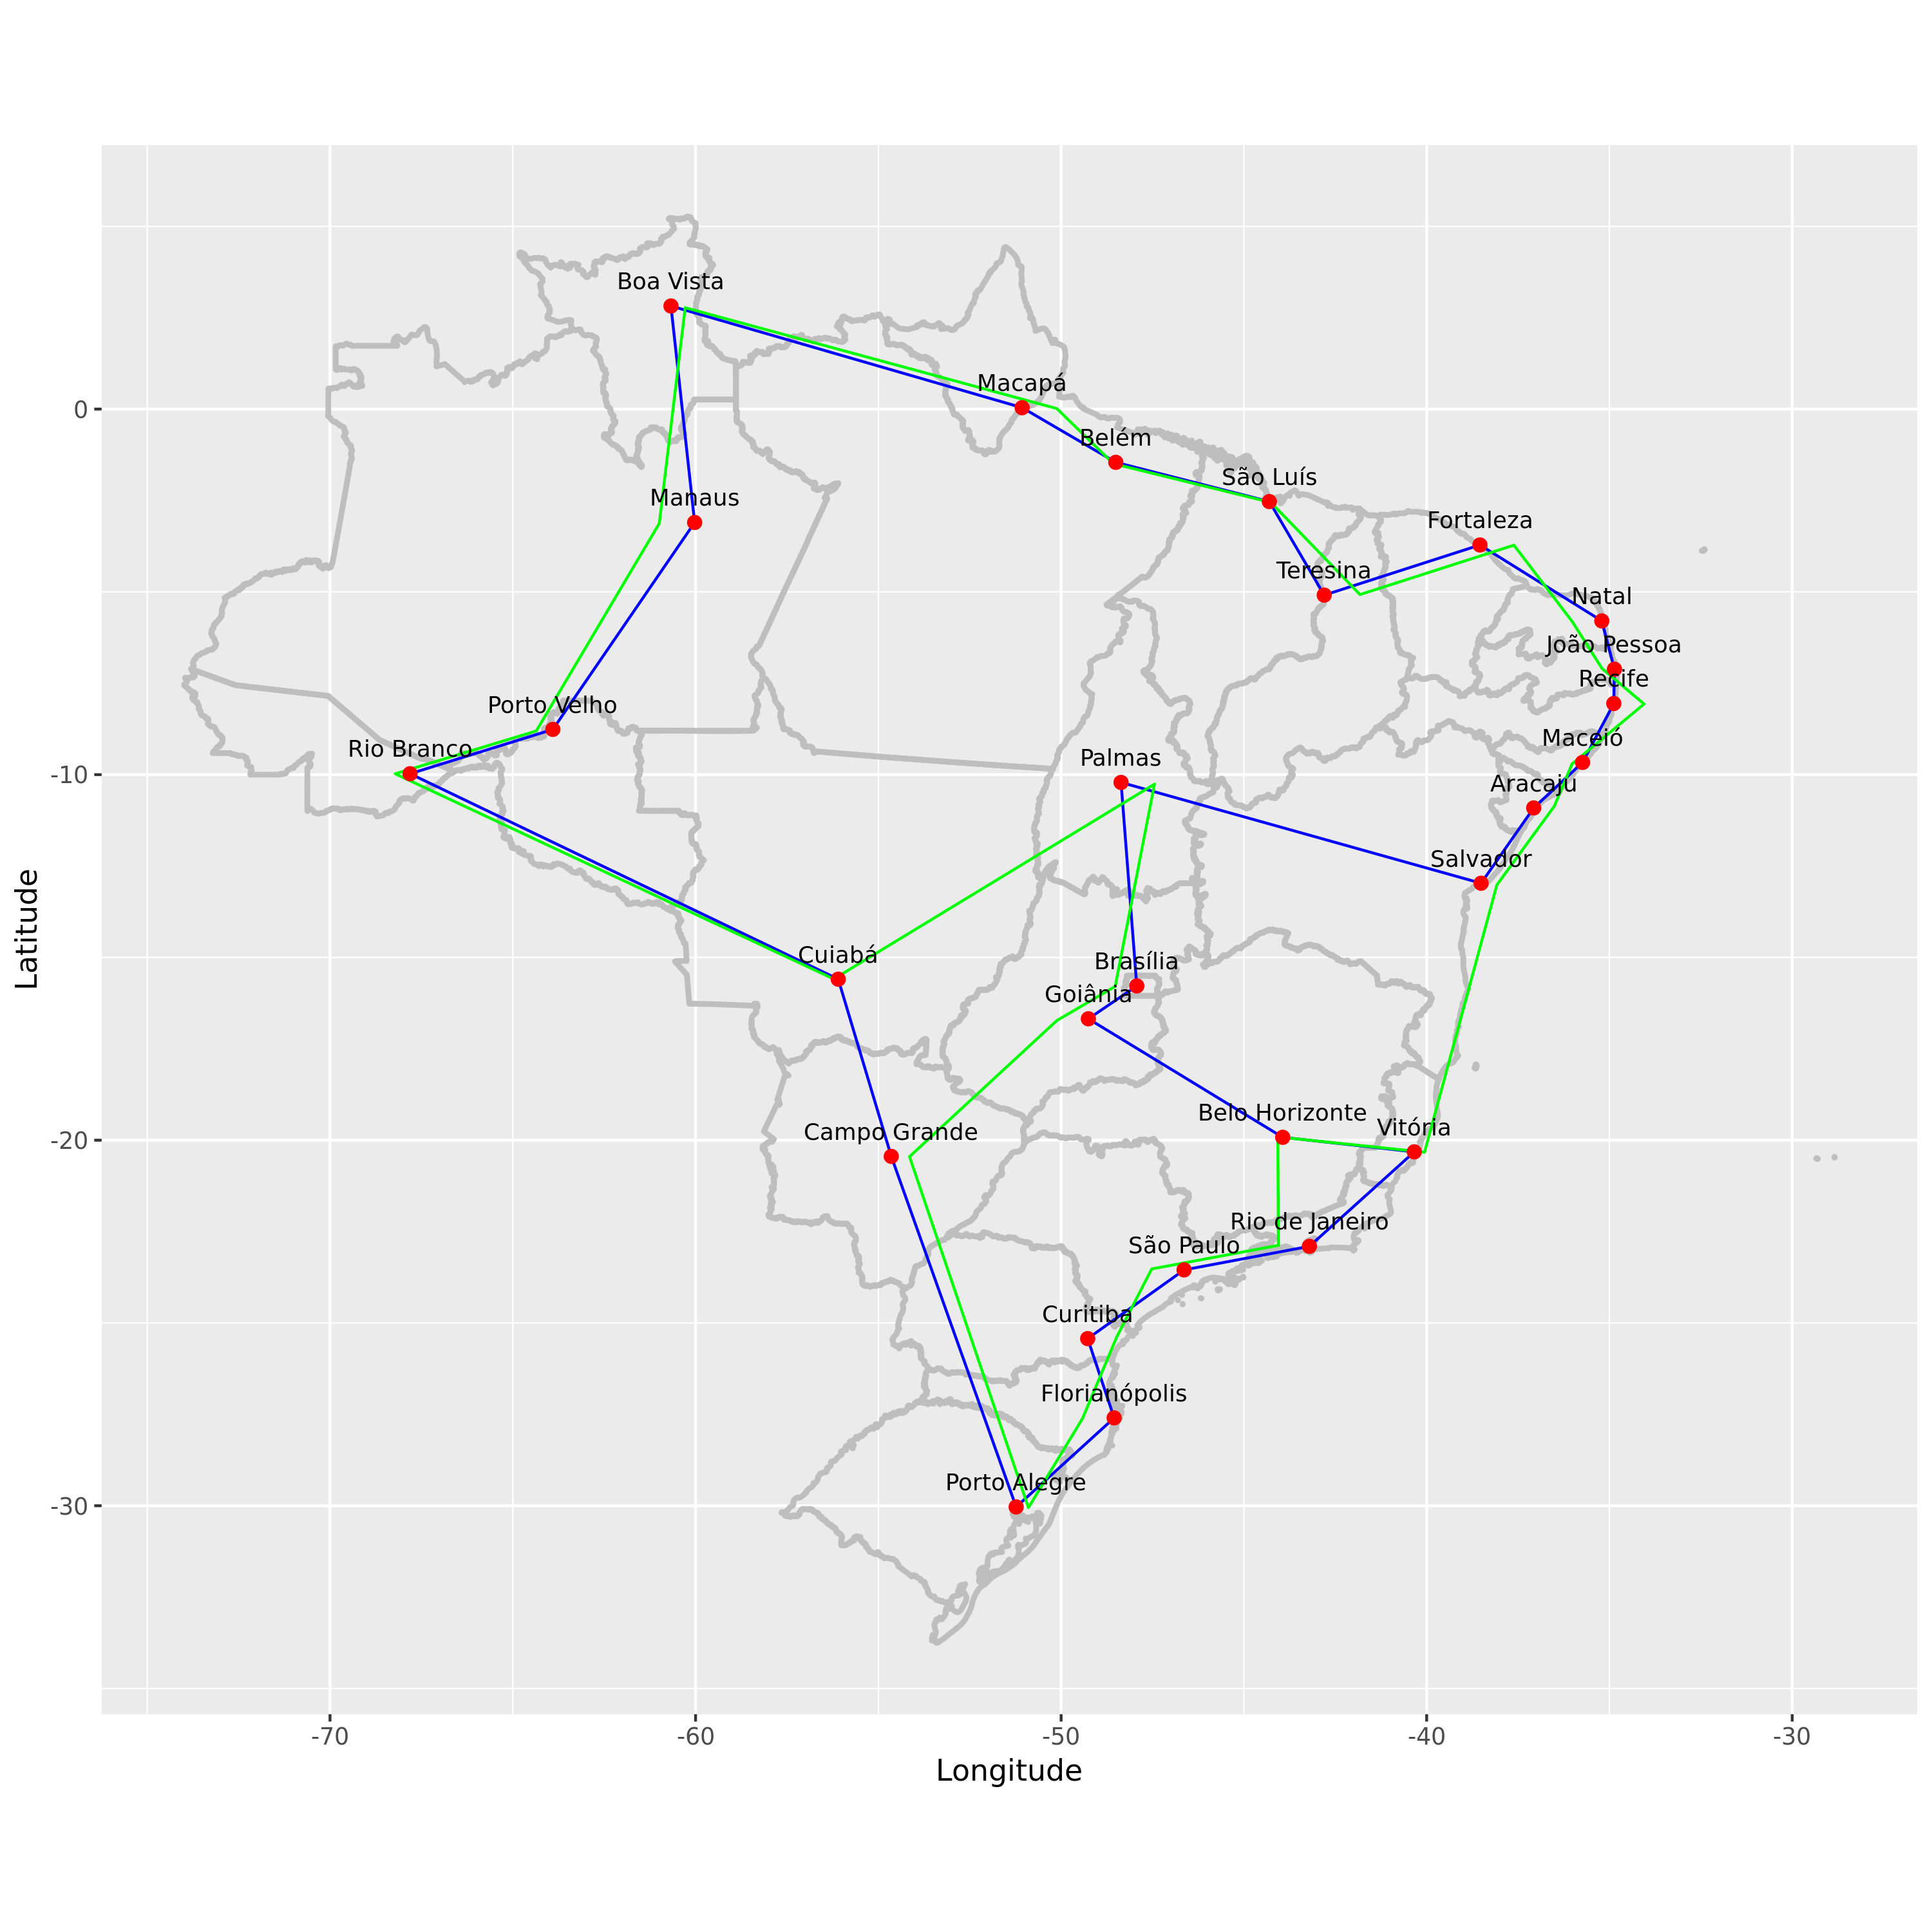

Fonte: Dan S. Reznik, *TSP for Brazilian State Capitals*. Acessível em https://github.com/dan-reznik/TSP-Brazilian-Capitals/blob/master/pics/tsp%20brazil%20ibge%20state%20polygons.png

# Todas as possíveis rotas

Embora saibamos que esta não é uma maneira prática de abordar casos com um número razoável de cidades, vamos começar com o algoritmo força bruta, ou seja, a enumeração de todas as possíveis rotas.

In [1]:
import matplotlib.pyplot as plt
import math
import random
import time
import itertools
import urllib
import csv

In [2]:
def forca_bruta(cidades):
    "Gera todas as possíveis rotas e escolhe a menor delas."
    return rota_mais_curta(todas_as_rotas(cidades))

def rota_mais_curta(rotas):
    "Escolhe a rota com menor tamanho."
    return min(rotas, key=tamanho_rota)

# TO DO: Tipos de dados: cidades, rotas, Funções: todas_as_rotas, tamanho_rota

**Detalhe**: no Python min(*conjunto, key=função*) significa achar o elemento que minimiza a função passada como chave.

## Representando uma rota

Uma rota pode ser representada por uma permutação das cidades a serem passadas. A ordem em que elas aparecem determina as distâncias a serem percorridas,pois duas cidades adjacentes representam um percurso.

In [3]:
todas_as_rotas = itertools.permutations

In [4]:
#Exemplo

cidades = [1, 2, 3, 4]
list(todas_as_rotas(cidades))

[(1, 2, 3, 4),
 (1, 2, 4, 3),
 (1, 3, 2, 4),
 (1, 3, 4, 2),
 (1, 4, 2, 3),
 (1, 4, 3, 2),
 (2, 1, 3, 4),
 (2, 1, 4, 3),
 (2, 3, 1, 4),
 (2, 3, 4, 1),
 (2, 4, 1, 3),
 (2, 4, 3, 1),
 (3, 1, 2, 4),
 (3, 1, 4, 2),
 (3, 2, 1, 4),
 (3, 2, 4, 1),
 (3, 4, 1, 2),
 (3, 4, 2, 1),
 (4, 1, 2, 3),
 (4, 1, 3, 2),
 (4, 2, 1, 3),
 (4, 2, 3, 1),
 (4, 3, 1, 2),
 (4, 3, 2, 1)]

In [4]:
def tamanho_rota(rota):
  "A distância total percorrida entre dois pares consecutivos em uma rota"
  return sum(distancia(rota[i-1], rota[i]) for i in range(len(rota)))

#TO DO: Função: distancia, Tipo de dados: cidades

**Detalhe**: Aqui usamos um truque específico do Python no qual

```
distancia(rota[-1], rota[0])
```

 se refere a distância entre o primeiro e o último elemento do vetor rota.

## Representando cidades

Cada cidade será representada como um ponto no espaço euclidiano $\mathbb{R}^2$ e a distância entre duas cidades é a distância euclidiana.

Neste caso temos um PCV simétrico, métrico, euclidiano.

Simétrico significa que a relação de distância é simétrica, ou seja: $\forall u, v \ : \ distancia(u,v) = distancia(v,u)$

Métrico significa que as distâncias obedecem desigualdades trianguelares, ou seja: $\forall u, v, w \ : \ distancia(u,v) \leq distancia(u, w) + distancia(w, v)$

E finalmente euclidiano significa que a distância euclidiana é a medida de distância utilizada. Essa definição é suficiente para as duas anteriores.




## Computando distâncias

No Python já temos a distância euclidiana disponível na biblioteca matemática, portanto vamos apenas renomeá-la por conveniência nos códigos a seguir:

In [5]:
distancia = math.dist

In [7]:
#Exemplo
A = [3, 0]
B = [0, 4]
print(distancia(A,B))

5.0


## Conjunto de cidades aleatórias

Para efeitos de nossos tester vamos considerar inicialmente a geração de instâncias aleatórias. Para isso vamos utilizar a geração de duplas que presentam as coordenadas euclidianas de cada cidade.

In [8]:
[ [random.randrange(1000), random.randrange(1000)] for c in range(7) ]

[[273, 695],
 [986, 363],
 [558, 246],
 [97, 538],
 [276, 930],
 [519, 685],
 [953, 997]]

Encapsulando isto em uma função e pensando nas dimensões da visualização, escrevemos a seguinte função de geração de uma instância aleatória.

In [6]:
def Cidades (n, largura=900, altura=600, rseed=233):
  "Faz um conjunto com n cidades, com coordenadas aleatórias no máximo (largura x alutura)"
  random.seed(rseed)
  return [ [random.randrange(largura), random.randrange(altura)] for c in range(n) ]

A seguir usamos a função de geração de um conjunto de 10 cidades e passamos para o algoritmo força bruta, cujo retorno a melhor rota para o caixeiro viajante, escrevendo uma sequência de coordenadas do espaço euclidiano, referentes à rota do caixeiro.

In [10]:
forca_bruta(Cidades(10))

([698, 178],
 [710, 14],
 [85, 104],
 [78, 243],
 [275, 239],
 [537, 236],
 [564, 209],
 [620, 232],
 [819, 495],
 [767, 291])

## Desenhando a solução

Para entender melhor o que se passa na solução apresentada pelos algoritmos vamos elaborar uma visualização simples da instância e da rota. Caso o parâmetro "completa" seja verdadeiro, vamos imprimir as arestas entre qualquer par de vértices.

In [7]:
def plot_rota(rota, completa=True):
  x = []
  y = []
  for i in range(len(rota)):
    x.append(rota[i][0])
    y.append(rota[i][1])

  if (completa):
    for i in range(len(rota)-1):
      for j in range(i+1,len(rota)):
        plt.plot([x[i], x[j]], [y[i], y[j]], color="LightGray", linewidth=1)

  for i in range(len(rota)):
    plt.plot([x[i], x[i-1]], [y[i], y[i-1]], color="Red", linewidth=2)

  plt.scatter(x, y, color="Blue", linewidth=3)

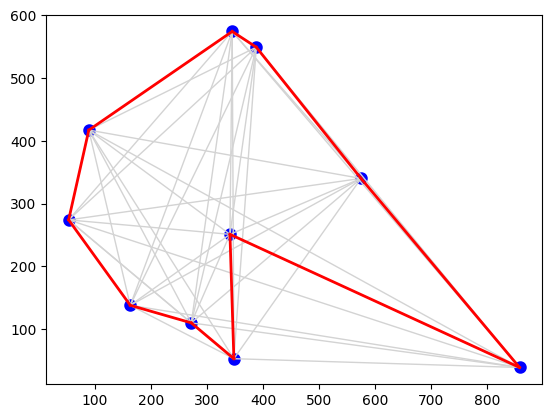

In [12]:
plot_rota(forca_bruta(Cidades(10, rseed=123)))

## Complexidade de enumerar todas as rotas
Demora cerca de 2 segundos na minha máquina para resolver este problema de 10 cidades. Em geral, a função TSP considera (n-1)! passeios para um problema de n cidades, e cada passeio tem n cidades, então o tempo total necessário para n cidades deve ser aproximadamente proporcional a n!. Isso significa que o tempo cresce rapidamente com o número de cidades. Realmente rapidamente. Esta tabela mostra o tempo real para resolver um problema de 10 cidades e o tempo esperado para resolver problemas maiores:



> |n	|tempo esperado
  |:- |:-
  |10	|10! rotas = 2 seg|
  |11	|2 seg × 11! / 10! ≈ 22 seg|
  |12	|2 seg × 12! / 10! ≈ 4 min|
  |14	|2 seg × 14! / 10! ≈ 13 horas|
  |16	|2 seg × 16! / 10! ≈ 200 dias|
  |18	|2 seg × 18! / 10! ≈ 112 anos|
  |25	|2 seg × 25! / 10! ≈ 270 bilhões de anos


Vamos precisar de uma forma melhor...

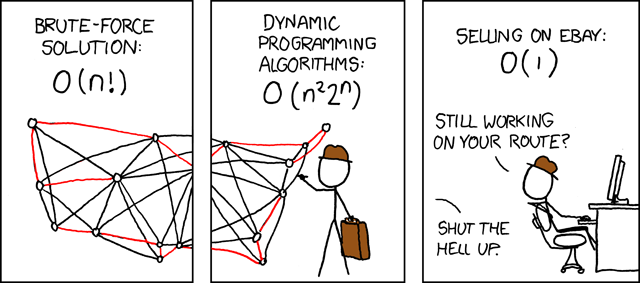

Fonte: Randall Munroe. *Travelling Salesman Problem*. Acessível em https://xkcd.com/399/

# Heurísticas construtivas

E se estivermos dispostos a nos contentar com um passeio curto, mas sem garantia de ser o mais curto? Então, podemos economizar bilhões de anos de tempo de computação: mostraremos algoritmos aproximados, que encontram passeios que normalmente estão dentro de 10% do passeio mais curto possível e podem lidar com milhares de cidades em poucos segundos. (Observação: existem algoritmos aproximados mais sofisticados que podem lidar com centenas de milhares de cidades e chegar a 0,01% ou mais do passeio mais curto possível.)

Então, como chegamos a um algoritmo aproximado? Aqui estão dois planos gerais de como criar um tour:



*   **Algoritmo do vizinho mais próximo**: Faz o tour ir de uma cidade até sua vizinha mais próxima. Repita.
*   **Algoritmo guloso**: Encontre a distância mais curta entre quaisquer duas cidades e inclua essa aresta no passeio sem formar trevos ou subciclos. Repita.         






Vamos expandir essas ideias em algoritmos completos.


## Vizinho mais próximo

Uma heurística construtiva que surge como uma primeira ideia é a seguinte: a partir de uma nó inicial, escolher para qual nó ir em seguida simplesmente selecionando o trajeto mais curto.

Esta é uma estratégia gulosa, pois a cada instante em que uma decisão precisa ser tomada para a construção da rota, o critério de otimização é usado sem que haja posteriormente uma reconsideração sobre aquela decisão.


In [8]:
def vizinho_mais_proximo(cidades):
    """Comece a rota na primeira cidade; a cada passo estenda a rota
    movendo-se da cidade anterior para a vizinha mais próxima
    que ainda não foi visitada."""
    primeira = cidades[0]
    rota = [primeira]
    inexploradas = cidades.copy()
    inexploradas.remove(primeira)
    while inexploradas:
        C = mais_proxima(rota[-1], inexploradas)
        rota.append(C)
        inexploradas.remove(C)
    return rota

def mais_proxima(c, cidades):
    "Encontre a cidade mais próxima da cidade c."
    return min(cidades, key=lambda x: distancia(c, x))

Detalhe: Em Python, assim como na teoria da computação, lambda (ou λ) é o símbolo para função, então "lambda x: distancia(c, x)" significa a função de x que calcula a distância de x para a cidade c.

Podemos comparar o rápido (porém inexado) algoritmo de vizinho mais próximo ao lento (porém exato) algoritmo de enumeração de todas as rotas para um conjunto pequeno:

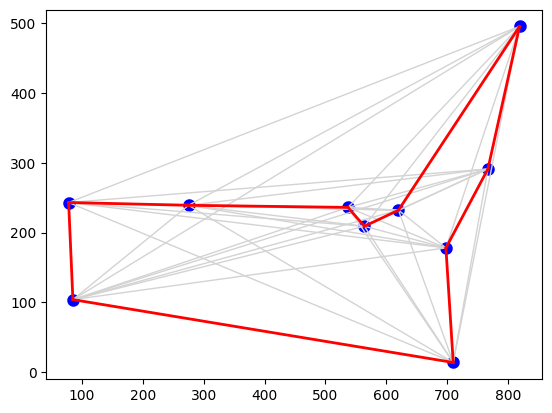

In [14]:
plot_rota(forca_bruta(Cidades(10)))

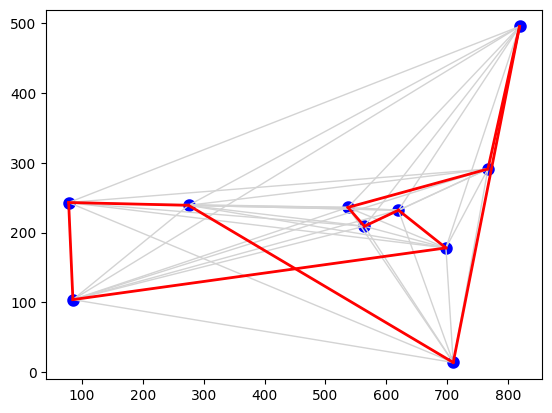

In [15]:
plot_rota(vizinho_mais_proximo(Cidades(10)))

In [16]:
Cidades(10)

[[698, 178],
 [537, 236],
 [819, 495],
 [564, 209],
 [85, 104],
 [275, 239],
 [710, 14],
 [78, 243],
 [620, 232],
 [767, 291]]

Outra forma de compara é saber a qual a distância percentual da melhor solução obtida para a solução ótima dada pelo algoritmo que enumera todas as rotas. Essa distância é conhecida como *gap*.

In [17]:
def gap(cidades):
    "Gap percentual entre o algoritmo de vizinho mais próximo e o algoritmo de todas as rotas."
    opt = tamanho_rota(forca_bruta(cidades))
    cnd = tamanho_rota(vizinho_mais_proximo(cidades))
    return  (cnd-opt)/opt

Para um resultado mais confiável podemos rodar um número maior de vezes.

In [18]:
gaps = sorted(gap(Cidades(10, rseed=i)) for i in range(10))
[ print("{0:0.2f}".format(x)) for x in gaps ]
mean = sum(gaps)/len(gaps)
print("Media = ", "{0:0.2f}".format(mean))
print("Desvio Padrão = ", "{0:0.2f}".format( ( sum([((x - mean) ** 2) for x in gaps]) / len(gaps) ) **0.5 ) )

0.00
0.00
0.00
0.15
0.19
0.20
0.23
0.24
0.25
0.29
Media =  0.15
Desvio Padrão =  0.11


Sabemos que é pior, mas podemos agora dar respostas para uma entrada com centenas ou milhares de cidades.

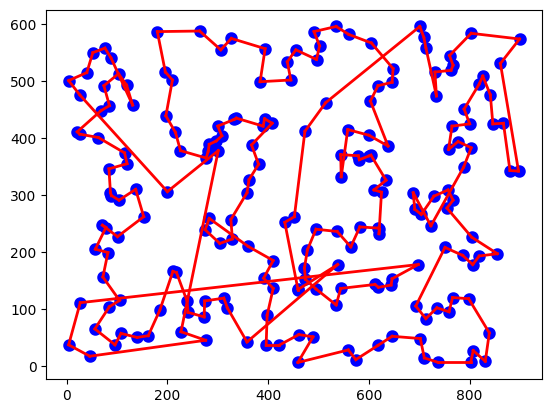

In [19]:
plot_rota(vizinho_mais_proximo(Cidades(200)),completa=False)

### Resultados podem variar dependendo do ponto de partida

A cidade inicial escolhida define toda a sequência de decisões que serão tomadas. Ao mudarmos a cidade inicial, é possível observar leves variações sobre a rota utilizada. Vamos então definir um algoritmo em que é possível selecionar o ponto de partida e avaliar como isso pode variar.

In [9]:
def vmp(cidades, inicio):
    """Comece a rota na primeira cidade; a cada passo estenda a rota
    movendo-se da cidade anterior para a vizinha mais próxima
    que ainda não foi visitada."""
    primeira = cidades[inicio]
    rota = [primeira]
    inexploradas = cidades.copy()
    inexploradas.remove(primeira)
    while inexploradas:
        C = mais_proxima(rota[-1], inexploradas)
        rota.append(C)
        inexploradas.remove(C)
    return rota


Se quisermos obter o melhor valor possível com essa heurística podemos executá-la para todos as cidades como ponto inicial.

In [10]:
def vmp_completa(cidades):
  return rota_mais_curta([ vmp(cidades, i) for i in range(len(cidades))])


A seguir vamos fazer comparações com as rotas geradas a partir de pontos diferentes e a melhor rota possível com esta estratégia.

Tamanho =  10799.126338818012


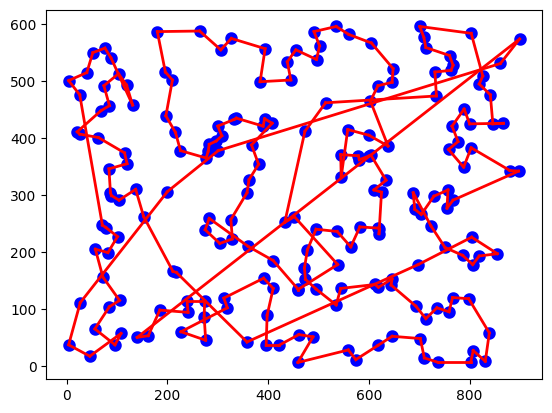

In [22]:
rota = vmp(Cidades(200), 122)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  10226.428015396952


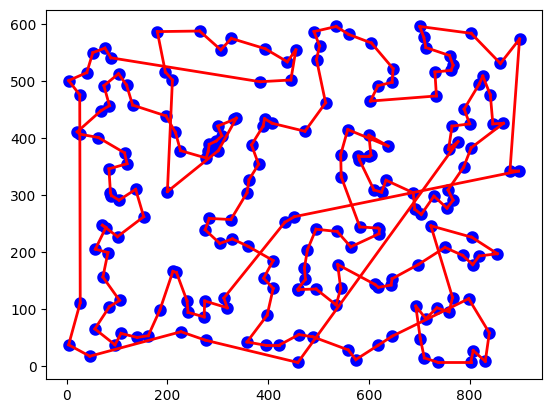

In [23]:
rota = vmp(Cidades(200), 78)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  9947.593114907942


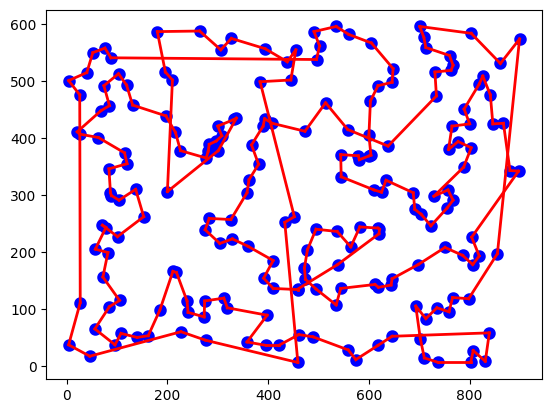

In [24]:
rota = vmp(Cidades(200), 13)
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

Tamanho =  9348.672220049299


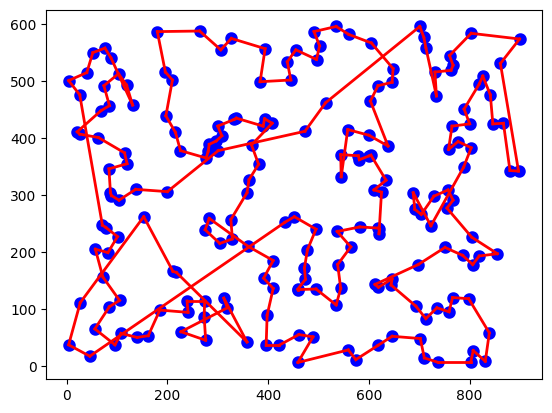

In [25]:
rota = vmp_completa(Cidades(200))
print("Tamanho = ", tamanho_rota(rota) )
plot_rota(rota,completa=False)

### Caso ruim: outliers

É possível construir casos onde a estratégia de partir de uma cidade para a mais próxima acaba gerando uma sobrecarga muito grande para as cidades deixadas para o final da rota.

Um exemplo pode ser visto a seguir.

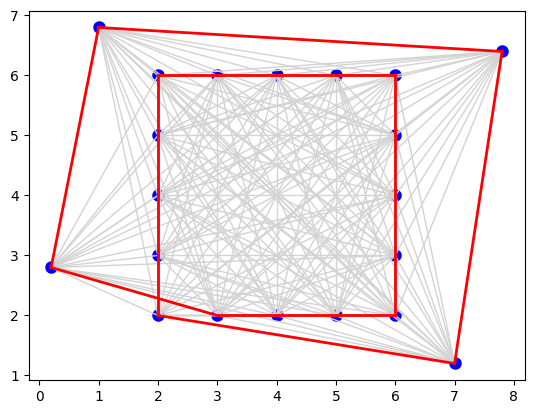

In [26]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(vizinho_mais_proximo(outliers))

## Heurística gulosa para o PCV

Uma possibilidade para superar a "miopia" das escolhas locais seria olhar para todas as arestas do grafo antes de tomar uma decisão. Neste sentido a heurística gulosa trabalha com o conjunto de todas as arestas e em ordem crescente de distância verifica se ela pode ser incluída na rota, sem que isto forme trevos ou subciclos.

De fato o algoritmo vai trabalha com um vetor que indica para cada vértice se ele pode se conectar a um outro vértice. Isto só é possível se estes candidatos a uma conexão forem nós terminais dos segmentos que compomos no processo de construção da rota. Guardamos portanto o segmento para qual cada vértica é um terminal. Note que inicialmente todos são terminais de um segmento unitário.

In [11]:
def guloso(cidades, verbose=False):
    """Percorre todas as arestas em ordem crescente e escolhe a primeira
        possível para fazer parte da solução"""
    arestas = ordena_arestas(cidades)
    terminais = [ [c] for c in range(len(cidades)) ] # A dict of {endpoint: segment}
    for [u,v] in arestas:
        if terminais[u] != [] and terminais[v] != [] and terminais[u] != terminais[v]:
            rota = unir(terminais, u, v, verbose)
            if len(rota) == len(cidades):
                rota = [ cidades[rota[i]] for i in range(len(cidades)) ]
                return rota

# TO DO: functions: ordena_arestas, unir

As arestas no algoritmo anterior são visitadas em ordem de tamanho. Para ordená-las utilizamos o código a seguir.

In [12]:
def ordena_arestas(cidades):
  "Retorna todas as arestas em uma lista ordenada pelo tamanho."
  arestas = [ [u, v] for u in range(len(cidades)) for v in range(len(cidades)) if u < v]
  return sorted(arestas, key=lambda aresta : distancia(cidades[aresta[0]], cidades[aresta[1]]))

Uma vez que identificamos uma aresta que conecta segmentos distintos pelos seus nós terminais, fazemos apelo a função unir definida abaixo para atualizar a lista de terminais.

In [13]:
def unir(terminais, u, v, verbose=False):
    "Une o segmento de u ao segmento de v, mantendo o vetor de terminais"
    useg, vseg = terminais[u], terminais[v]
    if (verbose) : print(useg, "(+) ", vseg, " => ", end='')
    if useg[-1] != u: useg.reverse()
    if vseg[0] != v: vseg.reverse()
    useg.extend(vseg)
    if (verbose) : print(useg)
    terminais[u] = []
    terminais[v] = []
    terminais[useg[0]] = terminais[useg[-1]] = useg
    return useg

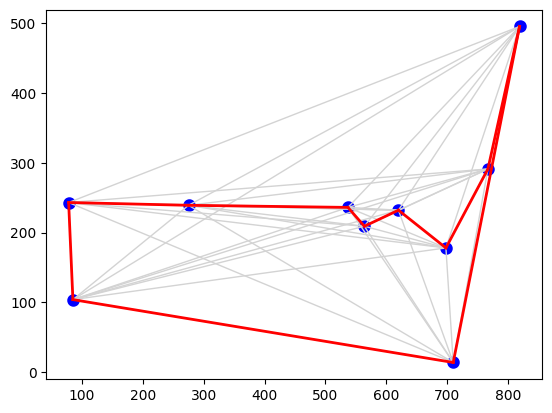

In [30]:
plot_rota(guloso(Cidades(10)))

A seguir observamos o desempenho do método, ligeiramente melhorado, para o caso dos outliers.

[0] (+)  [1]  => [0, 1]
[0, 1] (+)  [15]  => [1, 0, 15]
[1, 0, 15] (+)  [2]  => [15, 0, 1, 2]
[15, 0, 1, 2] (+)  [3]  => [15, 0, 1, 2, 3]
[15, 0, 1, 2, 3] (+)  [4]  => [15, 0, 1, 2, 3, 4]
[15, 0, 1, 2, 3, 4] (+)  [5]  => [15, 0, 1, 2, 3, 4, 5]
[15, 0, 1, 2, 3, 4, 5] (+)  [6]  => [15, 0, 1, 2, 3, 4, 5, 6]
[15, 0, 1, 2, 3, 4, 5, 6] (+)  [7]  => [15, 0, 1, 2, 3, 4, 5, 6, 7]
[15, 0, 1, 2, 3, 4, 5, 6, 7] (+)  [8]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8] (+)  [9]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9] (+)  [10]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10] (+)  [11]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] (+)  [12]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] (+)  [13]  => [15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
[15, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] (+)  [14]  => [15, 0,

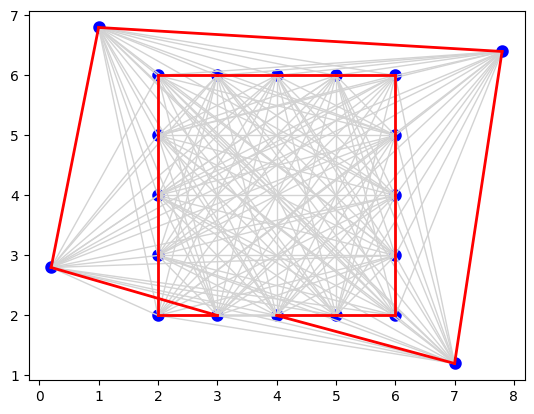

In [31]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(guloso(outliers, verbose=True))

## Procedimento de lapidação

Um dos ingredientes fundamentais para o funcionamento das metaheurísticas de trajetória é conseguir, a partir de uma solução, fazer ajustes para obter uma nova solução. Este processo de modificação é onipresente nesse tipo de heurística.

Aqui propomos uma modificação em que tomamos duas arestas $(u,v)$ e $(x,y)$ pertencentes a uma solução e propomos uma nova solução com as arestas $(u, x)$ e $(v, y)$. Para que isto seja possível também é preciso reverter (sem alteração de custo, já que estamos no caso simétrico) o caminho de $x$ para $y$ ou de $u$ para $v$

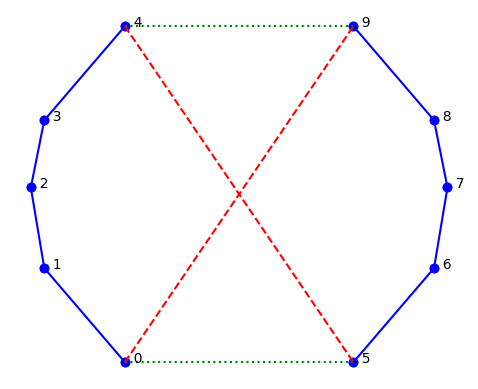

In [32]:
def plot_linhas(cidades, style='bo-'):
    "Plot lines to connect a series of points."
    x = [ p[0] for p in cidades ]
    y = [ p[1] for p in cidades ]
    plt.plot(x, y, style)
    plt.axis('scaled'); plt.axis('off')

def plot_nomes_linhas(cidades, *args):
    plot_linhas(cidades, 'bo')
    for (label, p) in enumerate(cidades):
        plt.text(p[0], p[1], '  '+str(label))
    # Draw lines indicated by args
    style = 'bo-'
    for arg in args:
        if isinstance(arg, str):
            style = arg
        else: # arg is a list of indexes into points, forming a line
            Xs = [cidades[i][0] for i in arg]
            Ys = [cidades[i][1] for i in arg]
            plt.plot(Xs, Ys, style)
    plt.axis('scaled'); plt.axis('off'); plt.show()

cross = [ [9, 3],  [3, 10],  [2, 16],  [3, 21],  [9, 28],
         [26, 3], [32, 10], [33, 16], [32, 21], [26, 28] ]

plot_nomes_linhas(cross, 'bo-', range(5), range(5, 10),
                          'g:', (4, 9), (0, 5),
                          'r--', (4, 5), (0, 9))

In [14]:
def reverter(rota, i, j):
    "Se a reversão da rota [i:j] for mais curta então reverta."
    u, v, x, y = rota[i-1], rota[i], rota[j-1], rota[j % len(rota)]
    if distancia(u, v) + distancia(x, y) > distancia(u, x) + distancia(v, y):
        rota[i:j] = reversed(rota[i:j])

A seguir escrevemos um algoritmo que passa por todos os seguimentos da rota e verifica se é vantajoso alterar a rota.

In [15]:
def alterar_rota(rota):
    "Procura todas as possíveis reversões de segmentos"
    segmentos = todos_segmentos(len(rota))
    while True:
      tamanho_atual = tamanho_rota(rota)
      for (u, v) in segmentos:
        reverter(rota, u, v)
      if tamanho_rota(rota) >= tamanho_atual: break
    return rota

def todos_segmentos(n):
    "Retorna todos os pares que formam segmentos de caminho numa rota de tamanho n."
    return [(u, u + t)
            for t in range(n, 1, -1)
            for u in range(n - t + 1)]

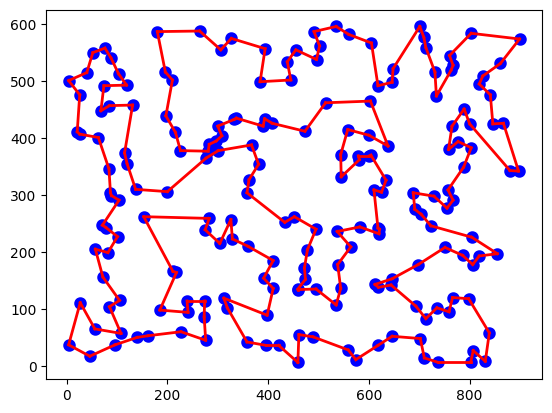

In [35]:
plot_rota(alterar_rota(vmp_completa(Cidades(200))), completa=False)

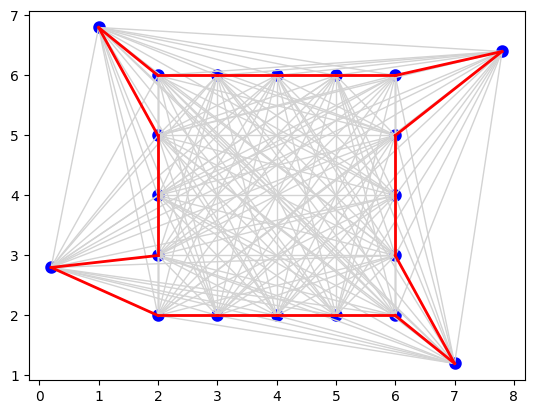

In [36]:
outliers = [[2, 2],  [2, 3],  [2, 4],  [2, 5],  [2, 6],
                 [3, 6],  [4, 6],  [5, 6],  [6, 6],
                 [6, 5],  [6, 4],  [6, 3],  [6, 2],
                 [5, 2],  [4, 2],  [3, 2],
                 [1, 6.8],  [7.8, 6.4],  [7, 1.2],  [0.2, 2.8]]

plot_rota(alterar_rota(guloso(outliers)))

# Exercícios



### Resolução dos exercícios 1, 2 e 3

Os custos incluem o retorno à cidade inicial e usam distância euclidiana. Os tempos são medidos em segundos com `perf_counter` e podem variar entre computadores. Uso as sementes 0, 1 e 2 para repetir as comparações nas mesmas instâncias. As melhorias são relativas ao método indicado, e não ao ótimo global.

In [16]:
from collections import Counter
from statistics import mean
from IPython.display import display, HTML
from html import escape

# Mostra tabelas sem depender de pandas.
def tabela(linhas, colunas):
    cabecalho = ''.join(f'<th>{escape(c)}</th>' for c in colunas)
    corpo = ''
    for linha in linhas:
        valores = []
        for coluna in colunas:
            valor = linha[coluna]
            texto = f'{valor:.4f}' if isinstance(valor, float) else str(valor)
            valores.append(f'<td>{escape(texto)}</td>')
        corpo += '<tr>' + ''.join(valores) + '</tr>'
    display(HTML('<table><thead><tr>' + cabecalho + '</tr></thead><tbody>' + corpo + '</tbody></table>'))

def medir(funcao, *args, **kwargs):
    inicio = time.perf_counter()
    rota = funcao(*args, **kwargs)
    return rota, time.perf_counter() - inicio

def validar_rota(rota, cidades):
    assert Counter(map(tuple, rota)) == Counter(map(tuple, cidades))


## Exercício 1 — Vizinho mais próximo com múltiplos pontos de partida

A heurística de vizinho mais próximo depende da cidade escolhida como ponto inicial. Já verificamos que executar o método para todos os possíveis pontos iniciais, como em `vmp_completa`, pode melhorar a qualidade da solução, mas também aumenta o custo computacional.

Implemente uma função

```python
vmp_amostral(cidades, proporcao=0.10, rseed=None)
```

que:

1. selecione aleatoriamente uma amostra contendo aproximadamente `proporcao × n` cidades;
2. utilize essas cidades como possíveis pontos iniciais;
3. execute a heurística de vizinho mais próximo para cada uma delas;
4. retorne a melhor rota encontrada.

Compare os seguintes métodos:

* `vmp`, utilizando apenas um ponto inicial;
* `vmp_amostral`, utilizando 10% das cidades como pontos iniciais;
* `vmp_completa`, utilizando todas as cidades como pontos iniciais.

Realize experimentos para diferentes tamanhos de instância, por exemplo:

$$
n \in \{50,100,200,500\}.
$$

Para cada método, registre:

* o valor da solução encontrada;
* o tempo de execução;
* a melhoria em relação à execução simples do vizinho mais próximo.

Sempre que possível, repita o experimento para diferentes instâncias aleatórias.

**Questões para discussão:**

1. Quanto ganhamos em qualidade utilizando vários pontos iniciais?
2. O ganho aumenta proporcionalmente ao número de pontos iniciais utilizados?
3. O aumento do custo computacional é compensado pela melhoria da solução?
4. Uma amostra de 10% parece suficiente? Experimente também outras proporções.

---



### Resolução do exercício 1 — Implementação e experimentos

A amostra é sorteada sem reposição e contém `ceil(proporcao * n)` pontos iniciais, com pelo menos um ponto quando há cidades. Um gerador local evita alterar o estado aleatório usado por outras funções. Também comparo 5%, 25% e 50%, além dos 10% pedidos.

In [17]:
def vmp_amostral(cidades, proporcao=0.10, rseed=None):
    if not 0 < proporcao <= 1:
        raise ValueError('A proporção deve estar no intervalo (0, 1].')
    if not cidades:
        return []
    quantidade = min(len(cidades), max(1, math.ceil(proporcao * len(cidades))))
    inicios = random.Random(rseed).sample(range(len(cidades)), quantidade)
    return rota_mais_curta(vmp(cidades, inicio) for inicio in inicios)

resultados_1 = []
for n in (50, 100, 200, 500):
    for semente in (0, 1, 2):
        cidades = Cidades(n, rseed=semente)
        rota_simples, tempo_simples = medir(vmp, cidades, 0)
        custo_simples = tamanho_rota(rota_simples)
        resultados_1.append({'n': n, 'Semente': semente, 'Método': 'VMP (início 0)',
                             'Inícios': 1, 'Custo': custo_simples,
                             'Tempo (s)': tempo_simples, 'Melhoria (%)': 0.0})
        for proporcao in (0.05, 0.10, 0.25, 0.50, 1.0):
            metodo = 'VMP completa' if proporcao == 1 else f'VMP amostral {proporcao:.0%}'
            if proporcao == 1:
                rota, tempo = medir(vmp_completa, cidades)
            else:
                rota, tempo = medir(vmp_amostral, cidades, proporcao, semente)
            validar_rota(rota, cidades)
            custo = tamanho_rota(rota)
            resultados_1.append({'n': n, 'Semente': semente, 'Método': metodo,
                                 'Inícios': math.ceil(proporcao * n), 'Custo': custo,
                                 'Tempo (s)': tempo,
                                 'Melhoria (%)': 100 * (custo_simples - custo) / custo_simples})
    print(f'Concluídas as três instâncias com {n} cidades.')

tabela(resultados_1, ['n', 'Semente', 'Método', 'Inícios', 'Custo', 'Tempo (s)', 'Melhoria (%)'])
resumo_1 = []
for n in (50, 100, 200, 500):
    for metodo in dict.fromkeys(r['Método'] for r in resultados_1):
        grupo = [r for r in resultados_1 if r['n'] == n and r['Método'] == metodo]
        resumo_1.append({'n': n, 'Método': metodo,
                         'Custo médio': mean(r['Custo'] for r in grupo),
                         'Tempo médio (s)': mean(r['Tempo (s)'] for r in grupo),
                         'Melhoria média (%)': mean(r['Melhoria (%)'] for r in grupo)})
tabela(resumo_1, ['n', 'Método', 'Custo médio', 'Tempo médio (s)', 'Melhoria média (%)'])


Concluídas as três instâncias com 50 cidades.


Concluídas as três instâncias com 100 cidades.


Concluídas as três instâncias com 200 cidades.


Concluídas as três instâncias com 500 cidades.


n,Semente,Método,Inícios,Custo,Tempo (s),Melhoria (%)
50,0,VMP (início 0),1,4871.6555,0.0002,0.0000
50,0,VMP amostral 5%,3,4727.7689,0.0007,2.9535
50,0,VMP amostral 10%,5,4727.7689,0.0012,2.9535
50,0,VMP amostral 25%,13,4727.7689,0.0030,2.9535
50,0,VMP amostral 50%,25,4603.7892,0.0059,5.4985
50,0,VMP completa,50,4585.1166,0.0124,5.8818
50,1,VMP (início 0),1,5363.3149,0.0002,0.0000
50,1,VMP amostral 5%,3,5396.2947,0.0008,-0.6149
50,1,VMP amostral 10%,5,5097.8605,0.0013,4.9494
50,1,VMP amostral 25%,13,5097.8605,0.0033,4.9494


n,Método,Custo médio,Tempo médio (s),Melhoria média (%)
50,VMP (início 0),5155.1074,0.0002,0.0000
50,VMP amostral 5%,5101.0096,0.0008,1.1070
50,VMP amostral 10%,4993.0221,0.0012,3.1245
50,VMP amostral 25%,4904.3951,0.0032,4.8190
50,VMP amostral 50%,4773.1611,0.0062,7.3863
50,VMP completa,4766.9369,0.0124,7.5140
100,VMP (início 0),7585.1689,0.0010,0.0000
100,VMP amostral 5%,7242.4191,0.0050,4.6515
100,VMP amostral 10%,7000.9879,0.0099,7.9260
100,VMP amostral 25%,6791.1525,0.0250,10.5280


### Evidências gráficas — exercício 1

Os gráficos comparam os custos, tempos e melhorias nas mesmas instâncias das tabelas. O tempo no primeiro painel de comparação usa escala logarítmica para mostrar métodos com durações muito diferentes. A segunda figura detalha as proporções para 500 cidades.

As médias usam três sementes e os valores são os mesmos das tabelas desta execução. Os gráficos sustentam as conclusões sobre as instâncias testadas; não demonstram uma superioridade geral ou o ótimo global.

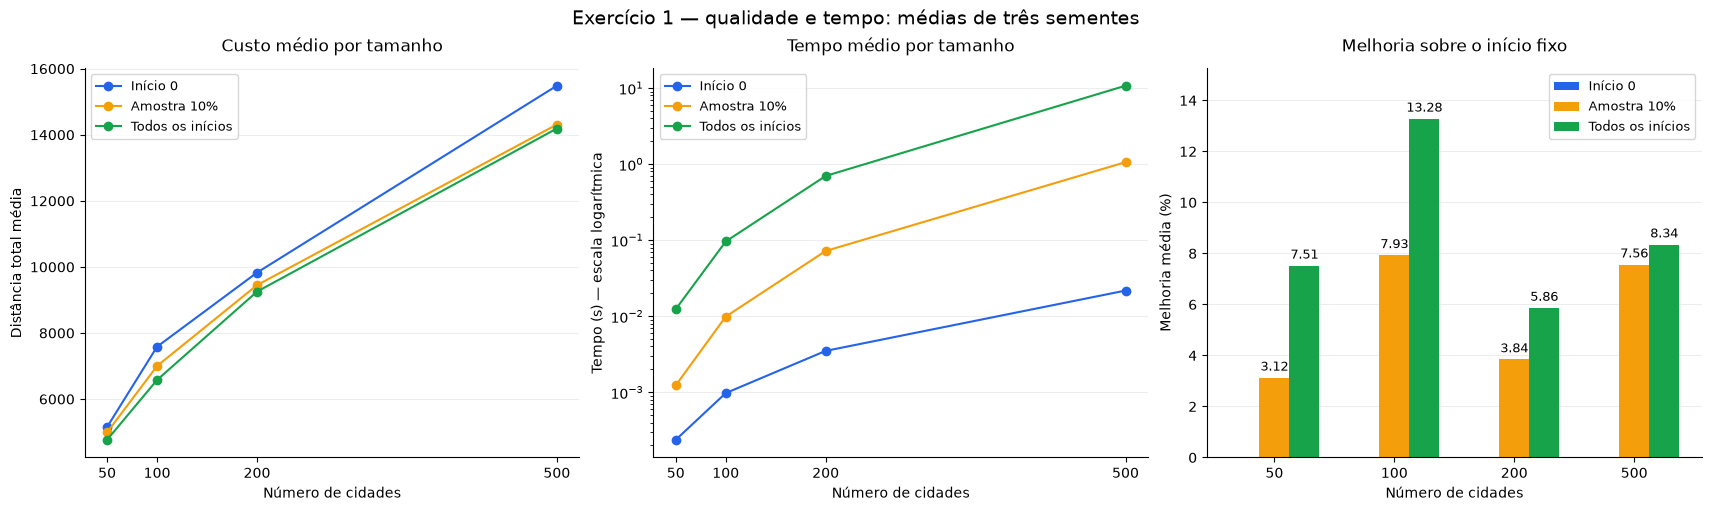

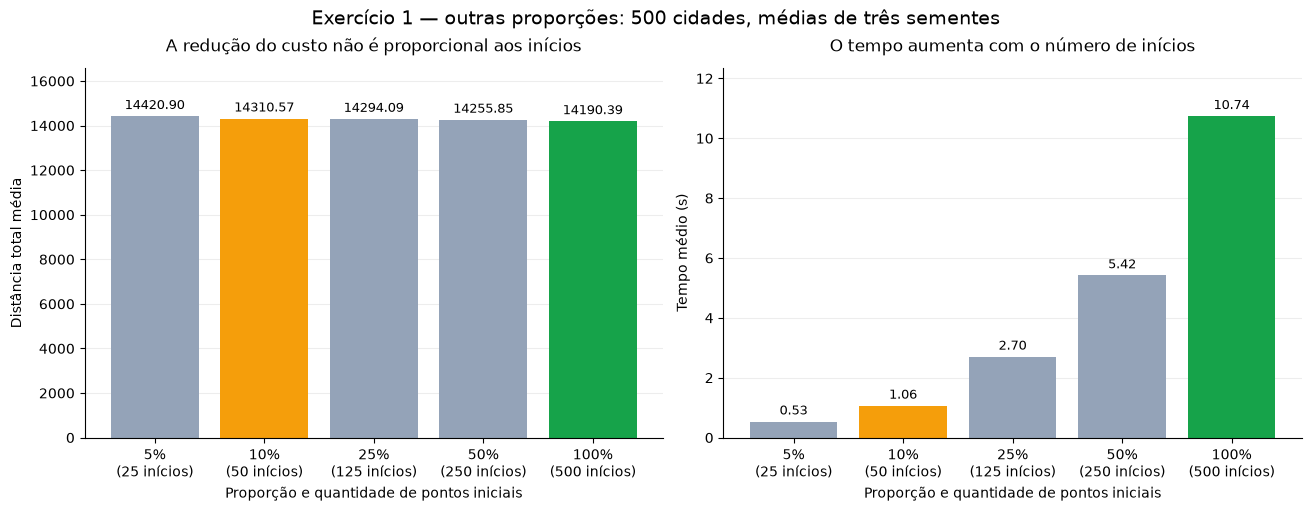

In [2]:
# Gráficos calculados a partir dos mesmos resultados das tabelas.
cores_pcv = ['#2563eb', '#f59e0b', '#16a34a', '#dc2626', '#9333ea']
def preparar_eixo(ax, titulo, ylabel):
    ax.set_title(titulo, fontsize=12, pad=12)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

def anotar_barras(ax, barras, casas=2):
    ax.bar_label(barras, labels=[f'{b.get_height():.{casas}f}' for b in barras],
                 padding=3, fontsize=9)
    ax.margins(y=0.15)

tamanhos_1 = [50, 100, 200, 500]
principais_1 = ['VMP (início 0)', 'VMP amostral 10%', 'VMP completa']
rotulos_1 = ['Início 0', 'Amostra 10%', 'Todos os inícios']
fig, eixos = plt.subplots(1, 3, figsize=(17, 5), layout='constrained')
for m, nome in enumerate(principais_1):
    grupo = [next(r for r in resumo_1 if r['n'] == n and r['Método'] == nome)
             for n in tamanhos_1]
    eixos[0].plot(tamanhos_1, [r['Custo médio'] for r in grupo], 'o-',
                  color=cores_pcv[m], label=rotulos_1[m])
    eixos[1].plot(tamanhos_1, [r['Tempo médio (s)'] for r in grupo], 'o-',
                  color=cores_pcv[m], label=rotulos_1[m])
    barras = eixos[2].bar([i + (m - 1) * 0.25 for i in range(4)],
                          [r['Melhoria média (%)'] for r in grupo],
                          width=0.25, color=cores_pcv[m], label=rotulos_1[m])
    if m > 0:
        anotar_barras(eixos[2], barras)
preparar_eixo(eixos[0], 'Custo médio por tamanho', 'Distância total média')
preparar_eixo(eixos[1], 'Tempo médio por tamanho', 'Tempo (s) — escala logarítmica')
eixos[1].set_yscale('log')
preparar_eixo(eixos[2], 'Melhoria sobre o início fixo', 'Melhoria média (%)')
eixos[2].set_xticks(range(4), tamanhos_1)
for ax in eixos[:2]:
    ax.set_xticks(tamanhos_1)
for ax in eixos:
    ax.set_xlabel('Número de cidades')
    ax.legend(fontsize=9)
fig.suptitle('Exercício 1 — qualidade e tempo: médias de três sementes', fontsize=14)
plt.show()

proporcoes_1 = [5, 10, 25, 50, 100]
nomes_proporcoes = ['VMP amostral 5%', 'VMP amostral 10%',
                   'VMP amostral 25%', 'VMP amostral 50%', 'VMP completa']
grupo_500 = [next(r for r in resumo_1 if r['n'] == 500 and r['Método'] == nome)
             for nome in nomes_proporcoes]
fig, eixos = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')
for ax, campo, titulo, ylabel, casas in (
    (eixos[0], 'Custo médio', 'A redução do custo não é proporcional aos inícios',
     'Distância total média', 2),
    (eixos[1], 'Tempo médio (s)', 'O tempo aumenta com o número de inícios',
     'Tempo médio (s)', 2)):
    barras = ax.bar(range(5), [r[campo] for r in grupo_500],
                    color=['#94a3b8', '#f59e0b', '#94a3b8', '#94a3b8', '#16a34a'])
    preparar_eixo(ax, titulo, ylabel)
    anotar_barras(ax, barras, casas)
    ax.set_xticks(range(5), [f'{p}%\n({p * 5} inícios)' for p in proporcoes_1])
    ax.set_xlabel('Proporção e quantidade de pontos iniciais')
fig.suptitle('Exercício 1 — outras proporções: 500 cidades, médias de três sementes',
              fontsize=14)
plt.show()


### Discussão do exercício 1

**1. Quanto ganhamos em qualidade utilizando vários pontos iniciais?**

Nos experimentos, percebi que a escolha da cidade inicial realmente influencia a qualidade da rota. O vizinho mais próximo sempre toma a decisão que parece melhor naquele momento, mas essa decisão altera quais cidades ficam disponíveis nas etapas seguintes. Por isso, começar em outro ponto pode mudar praticamente toda a sequência de visitas e também o tamanho da ligação usada para voltar à origem. Quando executamos o método várias vezes e guardamos a menor rota, temos mais oportunidades de encontrar uma sequência favorável.

Com uma amostra de 10%, a melhoria média em relação ao início fixo foi de **3,12% para 50 cidades, 7,93% para 100, 3,84% para 200 e 7,56% para 500**. Usando todas as cidades como início, as melhorias médias foram, respectivamente, **7,51%, 13,28%, 5,86% e 8,34%**. Esses percentuais são as médias das melhorias calculadas individualmente nas três sementes de cada tamanho. Um exemplo concreto é o caso de 500 cidades: o custo médio passou de **15485,92**, no VMP simples, para **14310,57**, na amostra de 10%, e **14190,39**, no VMP completo.

Minha interpretação é que vários pontos de partida ajudam a reduzir a dependência de uma escolha inicial arbitrária. Entretanto, o ganho varia conforme a distribuição das cidades: ele não cresceu continuamente com o tamanho da instância. Também não podemos interpretar essas melhorias como distância em relação ao ótimo, porque a referência utilizada foi o VMP com início 0. O VMP completo encontra a melhor rota entre as construídas por essa heurística, e não entre todas as rotas possíveis do PCV.

**2. O ganho aumenta proporcionalmente ao número de pontos iniciais utilizados?**

Não. O número de execuções cresce diretamente com a quantidade de pontos iniciais, mas a melhoria da rota não acompanha esse crescimento na mesma proporção. Isso acontece porque estamos selecionando o melhor resultado de várias tentativas. Uma nova tentativa só melhora a resposta se produzir uma rota menor que todas as anteriores; caso contrário, ela aumenta o tempo gasto sem alterar a solução escolhida. Além disso, cidades iniciais diferentes podem gerar rotas muito parecidas ou até o mesmo ciclo em sentidos ou posições iniciais diferentes.

Nas instâncias de 500 cidades, passar de 10% para 25% aumentou a quantidade de inícios de **50 para 125**, enquanto a melhoria média em relação ao VMP simples passou apenas de **7,56% para 7,66%**, cerca de **0,10 ponto percentual**. Ao usar 50% dos inícios, a melhoria foi de **7,92%**; com todos os inícios, chegou a **8,34%**. Assim, multiplicar o número de tentativas trouxe benefícios adicionais, mas pequenos nesse caso. Para 100 cidades, a execução completa trouxe um ganho adicional maior, o que mostra que a intensidade desse efeito também depende da instância.

Há um detalhe na comparação das amostras: proporções diferentes não necessariamente usam conjuntos encaixados uns nos outros, mesmo com a mesma semente. Portanto, uma amostra maior pode deixar de incluir algum início favorável da menor. Se mantivéssemos os inícios anteriores e apenas acrescentássemos novos, o melhor custo nunca poderia piorar. Essa garantia depende de preservar os candidatos já avaliados, e não apenas de aumentar a quantidade de pontos sorteados.

**3. O aumento do custo computacional é compensado pela melhoria da solução?**

Na minha avaliação, a resposta depende do tamanho do problema e do valor que damos à redução do custo da rota. Nas instâncias de 500 cidades, os tempos médios foram de aproximadamente **0,0217 s para o VMP simples, 1,06 s para a amostra de 10% e 10,74 s para o VMP completo**. Portanto, a amostra já exigiu bem mais trabalho que uma única execução, mas reduziu o custo médio de forma relevante. A execução completa gastou aproximadamente dez vezes o tempo da amostra para obter uma rota cujo custo médio foi apenas **0,84% menor que o da amostra**, considerando a amostra como referência dessa redução.

Esse comportamento pode ser explicado pelo número de avaliações realizadas. Em uma execução do VMP, procuramos a cidade mais próxima entre as que ainda não foram visitadas. O total dessas comparações é proporcional a \(n+(n-1)+\cdots+1\), resultando em custo da ordem de \(O(n^2)\). Com \(m\) inícios, o custo passa a ser \(O(mn^2)\). Se usamos todos os inícios, \(m=n\), e temos \(O(n^3)\). Uma amostra de proporção fixa também tem ordem \(O(n^3)\) quando \(n\) cresce, mas com menos execuções: 10% usa aproximadamente um décimo dos inícios do método completo.

Para uma situação em que precisamos responder rapidamente, eu consideraria os 10% uma escolha interessante. Já em um planejamento de rota que será utilizado muitas vezes, uma pequena economia de distância pode justificar alguns segundos adicionais de processamento. Nos testes com 50 cidades, até a execução completa levou apenas cerca de **0,0124 s**, então o custo absoluto era pequeno. Por isso, eu compararia o ganho de qualidade e o tempo efetivamente gasto. As medições são desta execução e podem variar em outro computador, principalmente nos casos que duram poucos milissegundos.

**4. Uma amostra de 10% parece suficiente? O que acontece com outras proporções?**

Os resultados sugerem que 10% é uma alternativa razoável, especialmente nas instâncias maiores, mas não que essa proporção seja suficiente em qualquer situação. Para 500 cidades, o custo médio dos 10% ficou aproximadamente **0,85% acima do custo médio do VMP completo**, tomando o completo como referência. Nesse tamanho, os 5% tiveram custo médio **14420,90**, os 10% **14310,57**, os 25% **14294,09** e os 50% **14255,85**. Os tempos médios foram, respectivamente, cerca de **0,53 s, 1,06 s, 2,70 s e 5,42 s**. Depois dos 10%, houve uma melhora relativamente pequena em troca de mais processamento.

Por outro lado, com 100 cidades, o custo médio dos 10% foi **7000,99**, enquanto o completo chegou a **6578,21**. Nesse caso, a amostra ficou cerca de **6,43% acima do completo**, uma diferença mais relevante. Portanto, a mesma proporção teve comportamentos diferentes nos tamanhos testados. Também devemos lembrar que 10% corresponde a apenas cinco inícios quando temos 50 cidades, mas a cinquenta quando temos 500. A proporção é a mesma, porém a quantidade absoluta de tentativas muda bastante.

Eu começaria com 10% quando tivesse um limite de tempo e aumentaria a proporção se os ganhos adicionais fossem importantes para a aplicação. Uma amostra pode deixar de fora o início 0 e até perder para o VMP simples. Uma alternativa seria sempre incluir esse início junto aos pontos sorteados, garantindo que o resultado não fosse pior que a referência. Como os experimentos usaram somente três sementes por tamanho, considero 10% uma escolha apoiada por estes resultados, e não uma conclusão definitiva. Uma avaliação mais ampla deveria variar mais instâncias e também as sementes usadas para sortear os pontos iniciais, mantendo cada conjunto de cidades fixo nessa segunda comparação.


## Exercício 2 — Heurística de inserção mais barata

Implemente uma nova heurística construtiva para o PCV baseada em **inserção mais barata**.

Considere uma rota parcial contendo uma aresta $(i,j)$. Se desejarmos inserir uma cidade $k$ entre $i$ e $j$, o aumento no custo da rota será

$$
\Delta(i,k,j)
=
d(i,k)+d(k,j)-d(i,j).
$$

A heurística deve funcionar da seguinte maneira:

1. construa uma pequena rota inicial;
2. considere todas as cidades que ainda não pertencem à rota;
3. para cada cidade $k$, considere todas as possíveis posições de inserção;
4. escolha a combinação $(i,k,j)$ que produz o menor aumento de custo $\Delta(i,k,j)$;
5. insira a cidade escolhida na rota;
6. repita o procedimento até que todas as cidades tenham sido inseridas.

Implemente uma função

```python
insercao_mais_barata(cidades)
```

que retorne a rota construída.

Compare essa heurística com:

* `vizinho_mais_proximo`;
* `guloso`.

Para uma mesma instância, desenhe as rotas obtidas pelos três métodos e compare seus custos.

**Questões para discussão:**

1. Qual dos métodos produz a melhor solução?
2. A resposta é sempre a mesma para diferentes instâncias?
3. Que diferença existe entre a decisão gulosa tomada pelo vizinho mais próximo e aquela tomada pela inserção mais barata?
4. É possível identificar visualmente decisões ruins tomadas durante a construção das rotas?

---



### Resolução do exercício 2 — Inserção mais barata

Começo com a cidade de índice 0 e sua vizinha mais próxima. Em cada passo, avalio todas as cidades restantes em todas as arestas da rota parcial, incluindo a aresta que fecha o ciclo. Uso índices para que cidades com coordenadas iguais continuem sendo visitas distintas. Em caso de empate, prevalece a primeira combinação encontrada.

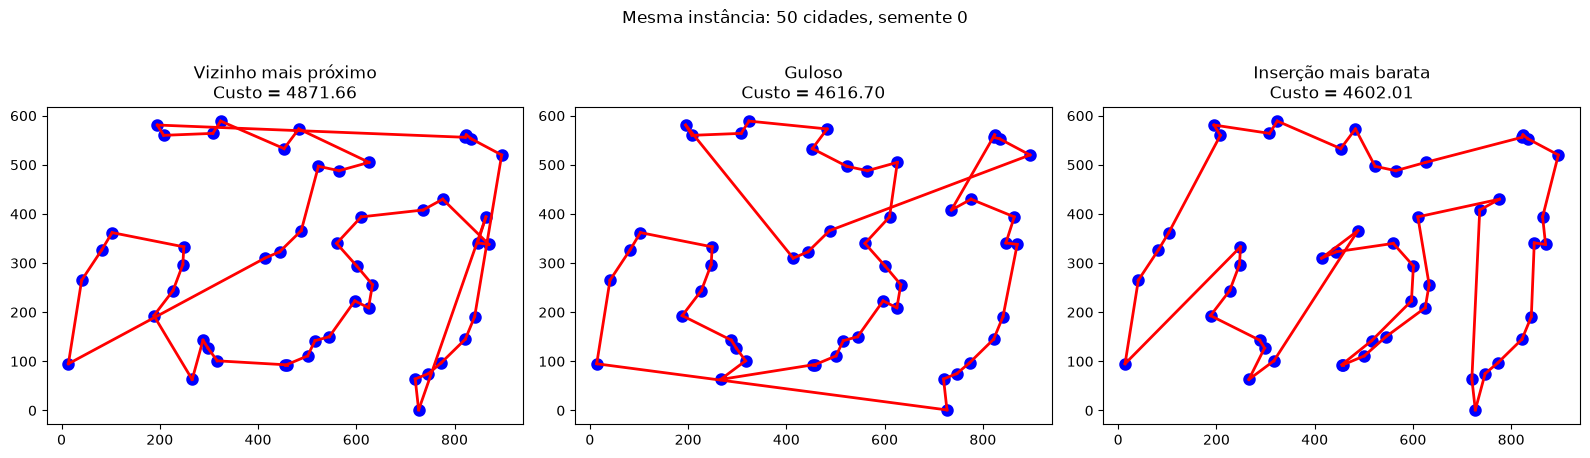

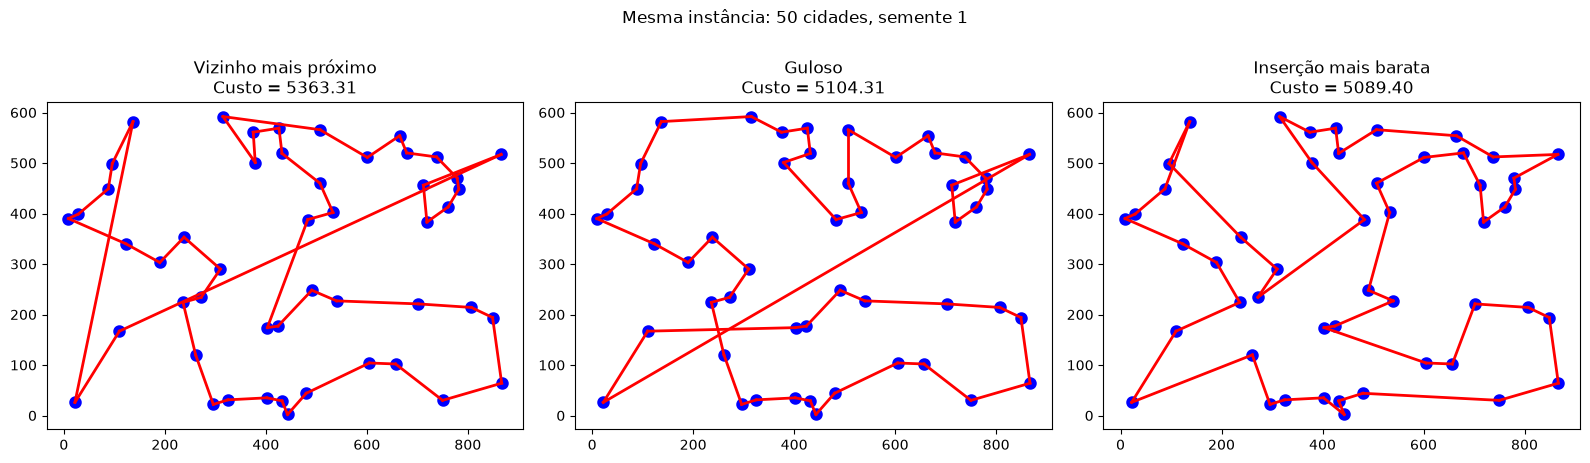

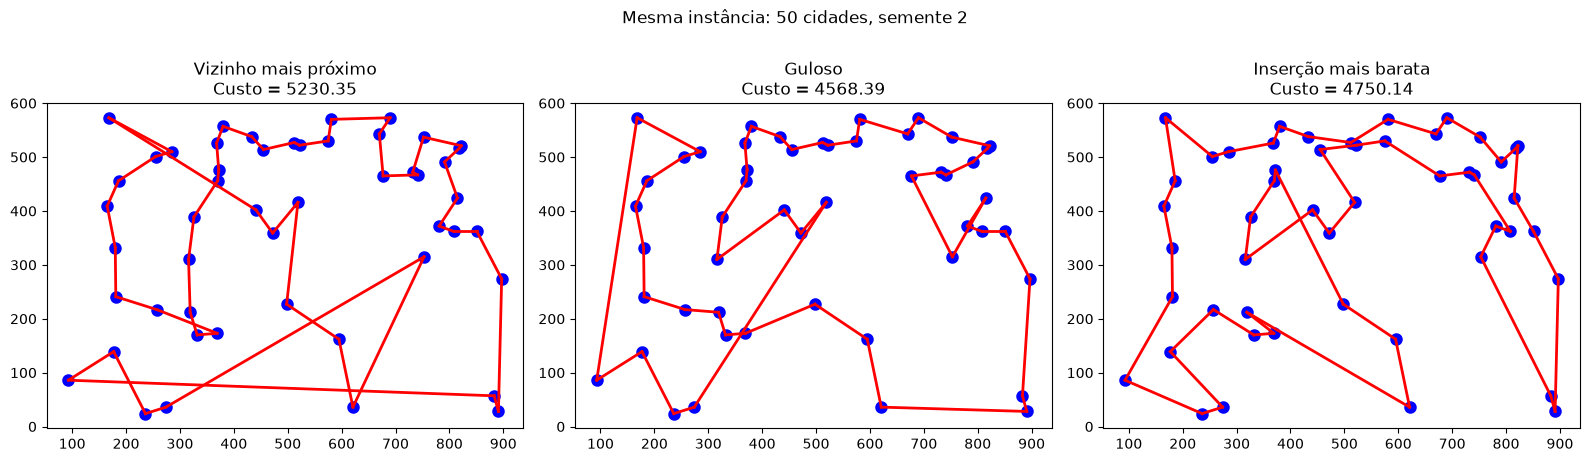

Semente,Método,Custo,Tempo (s)
0,Vizinho mais próximo,4871.6555,0.0002
0,Guloso,4616.7016,0.0006
0,Inserção mais barata,4602.0135,0.0039
1,Vizinho mais próximo,5363.3149,0.0002
1,Guloso,5104.3083,0.0007
1,Inserção mais barata,5089.3981,0.0046
2,Vizinho mais próximo,5230.3519,0.0002
2,Guloso,4568.3859,0.0007
2,Inserção mais barata,4750.1406,0.0042


In [18]:
def insercao_mais_barata(cidades):
    n = len(cidades)
    if n <= 2:
        return cidades.copy()
    # Matriz para evitar recalcular a mesma distância nas inserções.
    d = [[distancia(a, b) for b in cidades] for a in cidades]
    segunda = min(range(1, n), key=lambda k: d[0][k])
    rota = [0, segunda]
    restantes = [k for k in range(n) if k not in rota]
    while restantes:
        melhor_aumento = math.inf
        for k in restantes:
            for posicao, i in enumerate(rota):
                j = rota[(posicao + 1) % len(rota)]
                aumento = d[i][k] + d[k][j] - d[i][j]
                if aumento < melhor_aumento:
                    melhor_aumento = aumento
                    cidade_escolhida = k
                    posicao_escolhida = posicao + 1
        rota.insert(posicao_escolhida, cidade_escolhida)
        restantes.remove(cidade_escolhida)
    return [cidades[k] for k in rota]

metodos_2 = {'Vizinho mais próximo': vizinho_mais_proximo,
             'Guloso': guloso, 'Inserção mais barata': insercao_mais_barata}
resultados_2 = []
for semente in (0, 1, 2):
    cidades = Cidades(50, rseed=semente)
    fig, eixos = plt.subplots(1, 3, figsize=(16, 5))
    for eixo, (nome, metodo) in zip(eixos, metodos_2.items()):
        rota, tempo = medir(metodo, cidades)
        validar_rota(rota, cidades)
        custo = tamanho_rota(rota)
        resultados_2.append({'Semente': semente, 'Método': nome, 'Custo': custo, 'Tempo (s)': tempo})
        plt.sca(eixo)
        plot_rota(rota, completa=False)
        eixo.set_title(f'{nome}\nCusto = {custo:.2f}')
        eixo.set_aspect('equal')
    fig.suptitle(f'Mesma instância: 50 cidades, semente {semente}')
    plt.tight_layout()
    plt.show()
tabela(resultados_2, ['Semente', 'Método', 'Custo', 'Tempo (s)'])


### Evidências gráficas — exercício 2

Os gráficos mostram os custos por semente, o custo médio e o tempo médio de cada construção. As rotas desenhadas anteriormente complementam esta comparação com a análise de cruzamentos e ligações longas.

As médias usam três sementes e os valores são os mesmos das tabelas desta execução. Os gráficos sustentam as conclusões sobre as instâncias testadas; não demonstram uma superioridade geral ou o ótimo global.

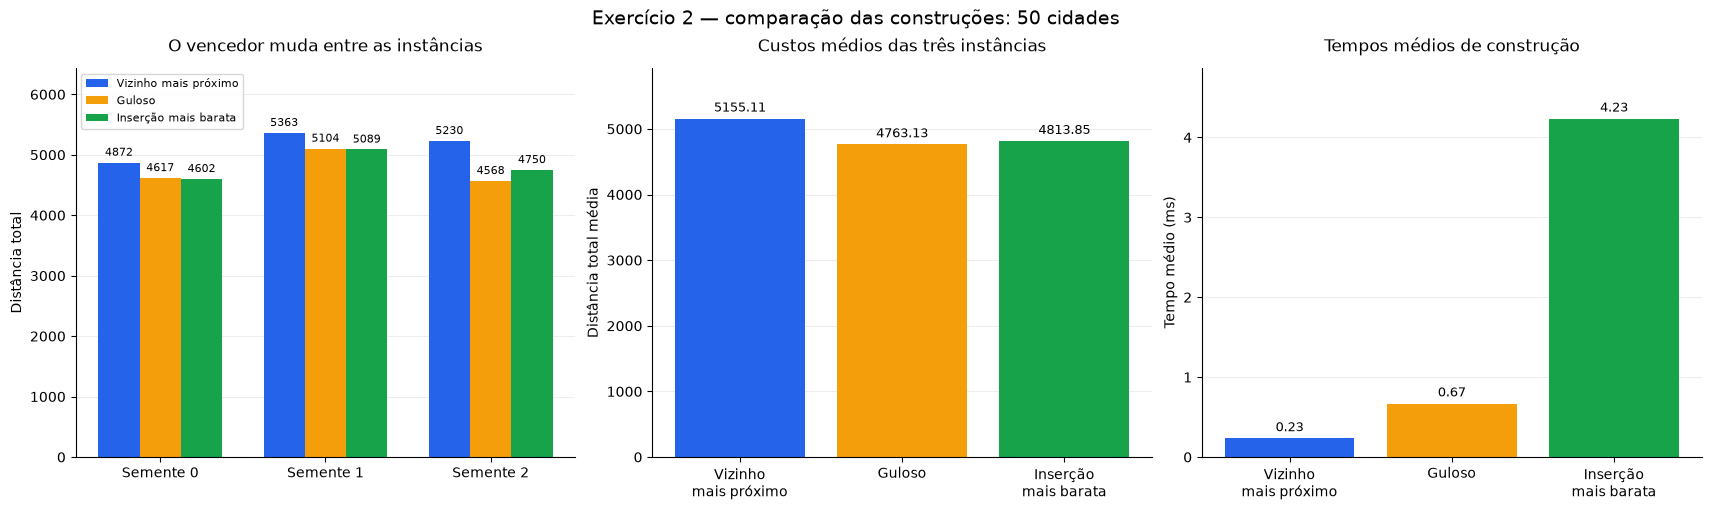

In [3]:
nomes_2 = ['Vizinho mais próximo', 'Guloso', 'Inserção mais barata']
rotulos_2 = ['Vizinho\nmais próximo', 'Guloso', 'Inserção\nmais barata']
fig, eixos = plt.subplots(1, 3, figsize=(17, 5), layout='constrained')
for m, nome in enumerate(nomes_2):
    valores = [next(r['Custo'] for r in resultados_2
                    if r['Semente'] == s and r['Método'] == nome) for s in (0, 1, 2)]
    barras = eixos[0].bar([s + (m - 1) * 0.25 for s in (0, 1, 2)],
                          valores, width=0.25, color=cores_pcv[m], label=nome)
    eixos[0].bar_label(barras, fmt='%.0f', padding=3, fontsize=8)
eixos[0].set_xticks([0, 1, 2], ['Semente 0', 'Semente 1', 'Semente 2'])
eixos[0].margins(y=0.2)
eixos[0].legend(fontsize=8, loc='upper left')
preparar_eixo(eixos[0], 'O vencedor muda entre as instâncias', 'Distância total')
for ax, campo, fator, titulo, ylabel in (
    (eixos[1], 'Custo', 1, 'Custos médios das três instâncias', 'Distância total média'),
    (eixos[2], 'Tempo (s)', 1000, 'Tempos médios de construção', 'Tempo médio (ms)')):
    valores = [fator * mean(r[campo] for r in resultados_2 if r['Método'] == nome)
               for nome in nomes_2]
    barras = ax.bar(range(3), valores, color=cores_pcv[:3])
    preparar_eixo(ax, titulo, ylabel)
    anotar_barras(ax, barras)
    ax.set_xticks(range(3), rotulos_2)
fig.suptitle('Exercício 2 — comparação das construções: 50 cidades', fontsize=14)
plt.show()


### Discussão do exercício 2

**1. Qual dos métodos produz a melhor solução?**

Nos testes com 50 cidades, a inserção mais barata venceu em duas das três instâncias, enquanto o guloso venceu na outra. Para a **semente 0**, os custos foram **4871,66 para o vizinho mais próximo, 4616,70 para o guloso e 4602,01 para a inserção mais barata**. Para a **semente 1**, os custos foram **5363,31, 5104,31 e 5089,40**, respectivamente. Nessas duas instâncias, a inserção foi melhor que o vizinho mais próximo, mas ficou muito próxima do guloso: a diferença entre inserção e guloso foi de aproximadamente 15 unidades em cada caso.

Na **semente 2**, o resultado mudou: o guloso produziu custo **4568,39**, a inserção mais barata **4750,14** e o vizinho mais próximo **5230,35**. Portanto, eu não apontaria um único vencedor para todas as instâncias. Se o critério for a quantidade de vitórias nesses três casos, a inserção se destacou. Se o critério for o custo médio nas três instâncias, o guloso foi melhor, com **4763,13**, contra **4813,85** da inserção e **5155,11** do vizinho mais próximo. Isso ocorre porque a vantagem do guloso na terceira instância foi maior que suas pequenas perdas nas duas primeiras.

Também considero importante separar qualidade e velocidade. A inserção mais barata levou cerca de **0,004 s por instância**, enquanto o guloso ficou abaixo de **0,001 s** e o vizinho mais próximo em torno de **0,0002 s**. Todos foram rápidos para 50 cidades, mas o custo adicional da inserção existe. Como o enunciado pede comparar o custo das rotas, usei a menor distância total, incluindo a volta à primeira cidade, para definir a melhor solução de cada instância. Esses valores não demonstram que alguma das rotas seja globalmente ótima.

**2. A resposta é sempre a mesma para diferentes instâncias?**

Não, e os próprios experimentos mostram isso. A inserção mais barata foi a melhor nas sementes 0 e 1, mas perdeu para o guloso na semente 2. A mudança de semente altera as posições das cidades e, consequentemente, as distâncias e as diferenças entre as escolhas disponíveis. Assim, a decisão que funciona bem em um conjunto de pontos pode não funcionar tão bem em outro.

As três heurísticas tomam decisões locais. O vizinho mais próximo privilegia a próxima ligação; o guloso privilegia as arestas curtas que ainda podem ser adicionadas; e a inserção privilegia o menor aumento imediato do ciclo parcial. Nenhuma delas, nas implementações utilizadas, examina todas as consequências futuras de cada escolha. É possível fazer uma escolha barata agora e deixar para o final cidades ou conexões que acabam exigindo um percurso longo.

Por isso, eu usaria os resultados para identificar tendências, mas evitaria afirmar que uma heurística é sempre superior. Também não diria que vencer em duas instâncias significa ser melhor em média, porque a tabela mostra justamente o contrário nesse conjunto. Uma comparação mais sólida deveria considerar mais sementes, outros tamanhos e diferentes distribuições de cidades, observando custo médio, variação dos resultados e tempo de execução. O desempenho pode depender tanto da heurística quanto da configuração inicial escolhida para ela.

**3. Que diferença existe entre a decisão gulosa do vizinho mais próximo e a da inserção mais barata?**

O vizinho mais próximo constrói uma sequência a partir da última cidade visitada. Se a cidade atual é \(i\), ele escolhe a cidade não visitada \(k\) que minimiza \(d(i,k)\). Sua decisão olha apenas a distância da próxima ligação. As cidades já colocadas na sequência mantêm sua posição, e o retorno à origem só é efetivamente definido quando a construção termina. Isso ajuda a explicar por que uma sequência de passos curtos pode acabar com uma ligação final longa.

A inserção mais barata trabalha com um ciclo parcial. Para cada cidade ainda não visitada, testa sua colocação entre cada par de cidades consecutivas desse ciclo. O critério é minimizar \(\Delta(i,k,j)=d(i,k)+d(k,j)-d(i,j)\): retiramos a ligação \((i,j)\) e colocamos as ligações \((i,k)\) e \((k,j)\). Dessa maneira, avaliamos o aumento total causado pela substituição de uma aresta. A cidade escolhida pode entrar em qualquer parte do ciclo, inclusive na aresta de fechamento.

Por exemplo, se a ligação atual tem custo 10 e a inserção cria duas ligações de custos 6 e 5, o aumento é **1**, e não 11, porque o custo 10 da ligação anterior deixa de existir. Outra inserção que cria ligações de custos 3 e 6 em uma aresta de custo 4 aumenta o ciclo em **5**. Portanto, ter uma ligação individual muito curta não significa ter a inserção mais vantajosa. Esse é o principal contraste entre os critérios que utilizei.

Apesar de analisar todas as posições do ciclo, a inserção continua sendo gulosa: escolhe o menor aumento naquele momento, sem garantir a melhor organização quando todas as cidades estiverem presentes. Na minha implementação, ela começa com a cidade 0 e sua vizinha mais próxima, e essa rota inicial também influencia as decisões seguintes. O guloso do notebook tem outro enfoque: ordena todas as arestas por tamanho e une segmentos por seus extremos, impedindo subciclos e graus maiores que dois durante a construção. Assim, os três métodos têm critérios locais diferentes, mesmo compartilhando a ideia de escolher uma opção imediatamente vantajosa.

**4. É possível identificar visualmente decisões ruins durante a construção das rotas?**

Sim, os desenhos ajudam a localizar características que merecem atenção, como cruzamentos, grandes desvios, ligações muito longas e um fechamento de rota que atravessa uma parte extensa da instância. Na figura da semente 0, por exemplo, a rota do vizinho mais próximo apresenta ligações diagonais longas e cruzamentos, e seu custo foi maior que o dos outros dois métodos. As rotas do guloso e da inserção também apresentam trechos que podem ser examinados pela busca local. Uma heurística pode ter um custo construtivo menor e ainda possuir oportunidades de melhoria.

No PCV euclidiano, o cruzamento de duas arestas com extremos distintos, em uma configuração não degenerada, é um indício especialmente forte: podemos retirar essas duas arestas e reconectar os caminhos por uma troca 2-opt que elimina o cruzamento e reduz a distância. A reversão de um dos segmentos mantém a rota válida, visitando as mesmas cidades. Esse tipo de análise relaciona uma característica visível do desenho com uma operação concreta de melhoria.

Mesmo assim, o gráfico final tem limites. Uma aresta longa pode ser necessária para alcançar uma cidade isolada, e uma rota sem cruzamentos ainda pode estar longe da melhor solução. Além disso, o desenho final não mostra a ordem em que cada decisão foi tomada: ele permite identificar um trecho desfavorável, mas não reconstruir com certeza o motivo da escolha. Para acompanhar as decisões durante a construção, seria necessário registrar ou desenhar as etapas intermediárias. Eu usaria os gráficos para levantar hipóteses e as distâncias ou trocas de melhoria para confirmar essas hipóteses.


## Exercício 3 — Construção seguida de busca local 2-opt

Neste exercício queremos investigar quanto a escolha da solução inicial influencia o resultado de uma busca local.

Considere as seguintes heurísticas construtivas:

* vizinho mais próximo;
* vizinho mais próximo com múltiplos pontos iniciais;
* heurística gulosa;
* inserção mais barata;
* heurística baseada em árvore geradora mínima.

Para cada método:

1. construa uma solução inicial;
2. registre o seu custo;
3. aplique repetidamente o procedimento de melhoria 2-opt apresentado no notebook;
4. continue enquanto existir uma troca que melhore a solução;
5. registre o custo da solução final e o tempo de execução.

Organize os resultados em uma tabela semelhante a:

| Método construtivo        | Custo inicial | Custo após 2-opt | Melhoria (%) | Tempo |
| ------------------------- | ------------: | ---------------: | -----------: | ----: |
| Vizinho mais próximo      |               |                  |              |       |
| VMP com múltiplos inícios |               |                  |              |       |
| Guloso                    |               |                  |              |       |
| Inserção mais barata      |               |                  |              |       |
| AGM                       |               |                  |              |       |

A melhoria percentual pode ser calculada por

$$
100\times
\frac{z_{\text{inicial}}-z_{\text{final}}}
     {z_{\text{inicial}}}.
$$

Repita o experimento para diferentes instâncias.

**Questões para discussão:**

1. Qual heurística costuma produzir as melhores soluções iniciais?
2. Após a aplicação do 2-opt, as diferenças entre os métodos diminuem?
3. A melhor solução inicial sempre conduz à melhor solução final?
4. Duas soluções iniciais diferentes podem conduzir a mínimos locais diferentes?
5. A qualidade da solução inicial continua sendo importante quando utilizamos busca local?

---

### Resolução do exercício 3 — Construção e busca local 2-opt

A comparação inclui uma AGM construída por Prim e percorrida em pré-ordem, como apoio para este exercício. Uso o procedimento `alterar_rota` apresentado no notebook, que repete as reversões até uma passagem completa não reduzir o custo. A rota inicial é copiada antes da busca local. Registro separadamente o tempo de construção e o de 2-opt; a coluna de tempo total soma os dois.

In [ ]:
def preordem(adj, raiz=0):
    if not adj:
        return []
    ordem, visitados, pilha = [], set(), [raiz]
    while pilha:
        u = pilha.pop()
        if u in visitados:
            continue
        visitados.add(u)
        ordem.append(u)
        pilha.extend(reversed(adj[u]))
    return ordem

def agm_pcv(cidades, raiz=0):
    n = len(cidades)
    if n == 0:
        return []
    if not 0 <= raiz < n:
        raise ValueError('Raiz fora dos índices das cidades.')
    adj = [[] for _ in cidades]
    na_arvore = [False] * n
    chave, pai = [math.inf] * n, [-1] * n
    chave[0] = 0
    for _ in range(n):
        u = min((i for i in range(n) if not na_arvore[i]), key=lambda i: chave[i])
        na_arvore[u] = True
        if pai[u] != -1:
            adj[u].append(pai[u])
            adj[pai[u]].append(u)
        for v in range(n):
            if not na_arvore[v]:
                peso = distancia(cidades[u], cidades[v])
                if peso < chave[v]:
                    chave[v], pai[v] = peso, u
    return [cidades[i] for i in preordem(adj, raiz)]

metodos_3 = {'Vizinho mais próximo': vizinho_mais_proximo,
             'VMP com múltiplos inícios (10%)': lambda c: vmp_amostral(c, 0.10, 42),
             'Guloso': guloso, 'Inserção mais barata': insercao_mais_barata, 'AGM': agm_pcv}
resultados_3 = []
for n in (50, 100, 200):
    for semente in (0, 1, 2):
        cidades = Cidades(n, rseed=semente)
        for nome, metodo in metodos_3.items():
            inicial, tempo_construcao = medir(metodo, cidades)
            custo_inicial = tamanho_rota(inicial)
            final, tempo_busca = medir(alterar_rota, inicial.copy())
            validar_rota(final, cidades)
            custo_final = tamanho_rota(final)
            assert custo_final <= custo_inicial + 1e-8
            resultados_3.append({'n': n, 'Semente': semente, 'Método': nome,
                                 'Custo inicial': custo_inicial, 'Custo após 2-opt': custo_final,
                                 'Melhoria (%)': 100 * (custo_inicial - custo_final) / custo_inicial,
                                 'Construção (s)': tempo_construcao, '2-opt (s)': tempo_busca,
                                 'Tempo total (s)': tempo_construcao + tempo_busca})
tabela(resultados_3, ['n', 'Semente', 'Método', 'Custo inicial', 'Custo após 2-opt',
                     'Melhoria (%)', 'Construção (s)', '2-opt (s)', 'Tempo total (s)'])
resumo_3 = []
for n in (50, 100, 200):
    for nome in metodos_3:
        grupo = [r for r in resultados_3 if r['n'] == n and r['Método'] == nome]
        resumo_3.append({'n': n, 'Método': nome,
                         'Custo inicial médio': mean(r['Custo inicial'] for r in grupo),
                         'Custo final médio': mean(r['Custo após 2-opt'] for r in grupo),
                         'Melhoria média (%)': mean(r['Melhoria (%)'] for r in grupo),
                         'Tempo médio total (s)': mean(r['Tempo total (s)'] for r in grupo)})
tabela(resumo_3, ['n', 'Método', 'Custo inicial médio', 'Custo final médio',
                  'Melhoria média (%)', 'Tempo médio total (s)'])


n,Semente,Método,Custo inicial,Custo após 2-opt,Melhoria (%),Construção (s),2-opt (s),Tempo total (s)
50,0,Vizinho mais próximo,4871.6555,4008.8098,17.7116,0.0002,0.0024,0.0026
50,0,VMP com múltiplos inícios (10%),4603.7892,3939.7744,14.4232,0.0011,0.0032,0.0043
50,0,Guloso,4616.7016,4164.2963,9.7993,0.0006,0.0026,0.0033
50,0,Inserção mais barata,4602.0135,4016.7421,12.7177,0.0035,0.0019,0.0054
50,0,AGM,4850.6415,4164.2963,14.1496,0.0008,0.0028,0.0036
50,1,Vizinho mais próximo,5363.3149,4517.1799,15.7763,0.0002,0.0028,0.0030
50,1,VMP com múltiplos inícios (10%),5293.2506,4259.3934,19.5316,0.0013,0.0019,0.0033
50,1,Guloso,5104.3083,4331.4659,15.1410,0.0011,0.0029,0.0040
50,1,Inserção mais barata,5089.3981,4553.5705,10.5283,0.0038,0.0029,0.0067
50,1,AGM,5903.0886,4480.8851,24.0925,0.0005,0.0029,0.0034


n,Método,Custo inicial médio,Custo final médio,Melhoria média (%),Tempo médio total (s)
50,Vizinho mais próximo,5155.1074,4138.0417,19.7167,0.0033
50,VMP com múltiplos inícios (10%),4838.2911,4071.4233,15.6690,0.0043
50,Guloso,4763.1319,4184.2351,12.0452,0.0035
50,Inserção mais barata,4813.8507,4344.4125,9.7642,0.0069
50,AGM,5394.3593,4333.1931,19.3470,0.0044
100,Vizinho mais próximo,7585.1689,6043.7460,20.2619,0.0128
100,VMP com múltiplos inícios (10%),6849.9640,6084.7409,10.9306,0.0235
100,Guloso,6727.8615,6013.2879,10.5240,0.0337
100,Inserção mais barata,6895.5474,6429.6714,6.8048,0.0417
100,AGM,7581.7337,6168.5601,18.4869,0.0178


### Evidências gráficas — exercício 3

Os gráficos comparam custos antes e depois do 2-opt, diferenças relativas por instância, contraexemplos de inversão da classificação e a relação entre qualidade final e tempo total.

As médias usam três sementes e os valores são os mesmos das tabelas desta execução. Os gráficos sustentam as conclusões sobre as instâncias testadas; não demonstram uma superioridade geral ou o ótimo global.

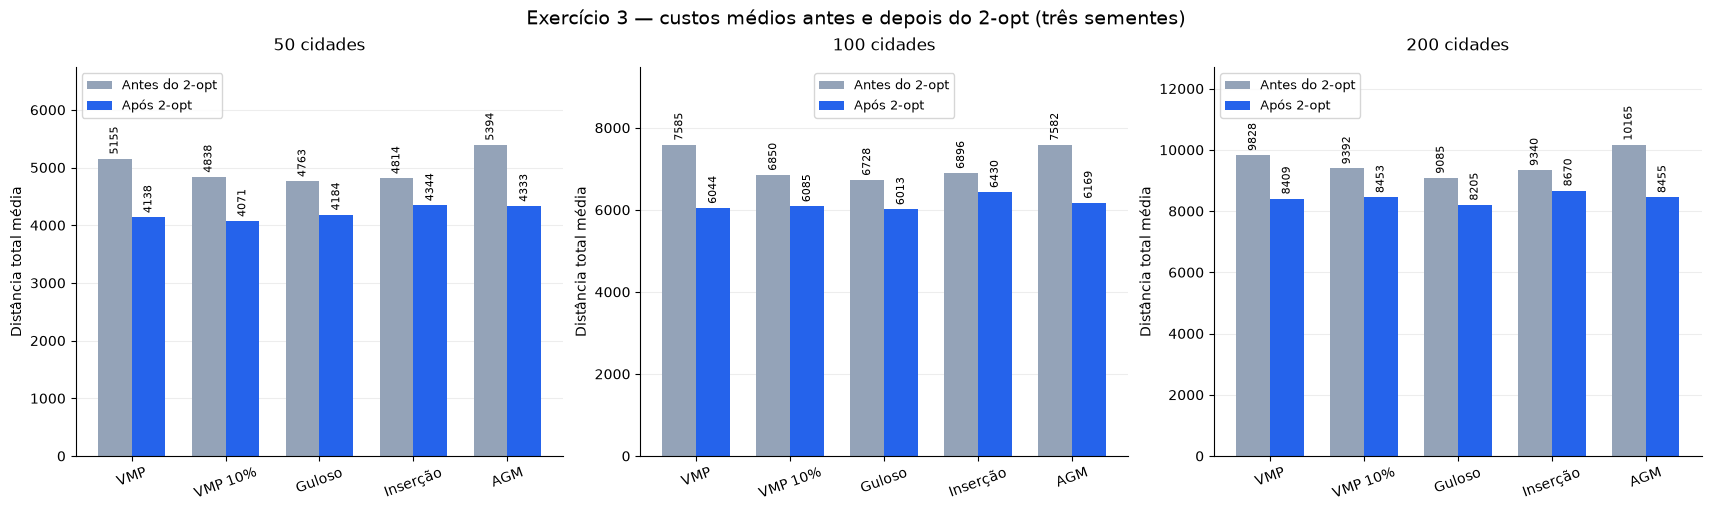

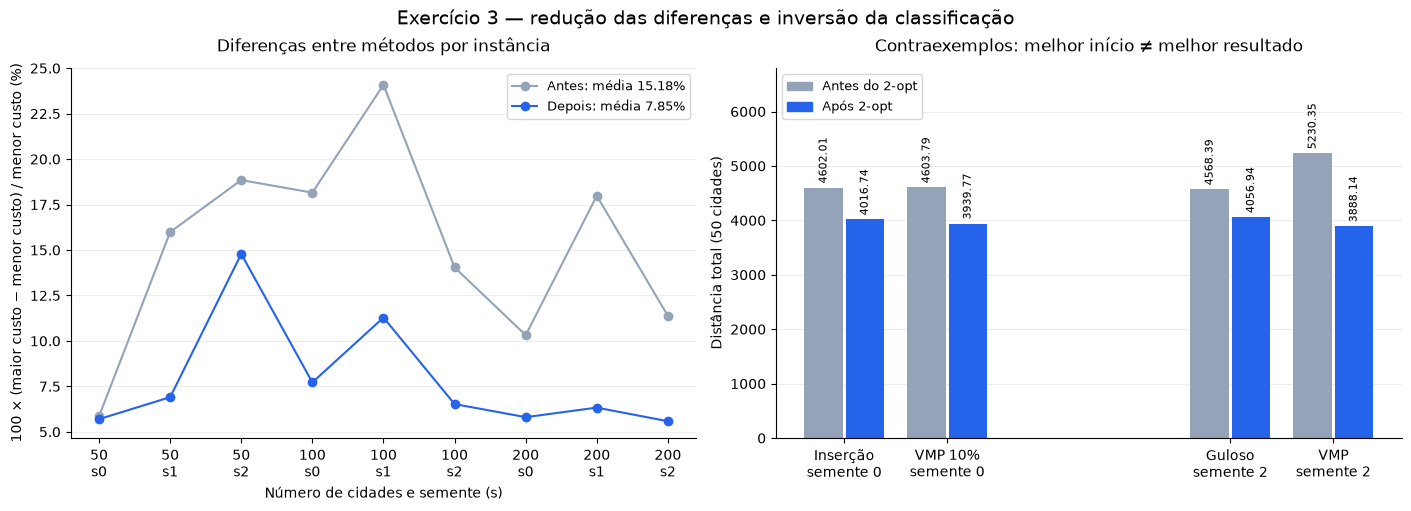

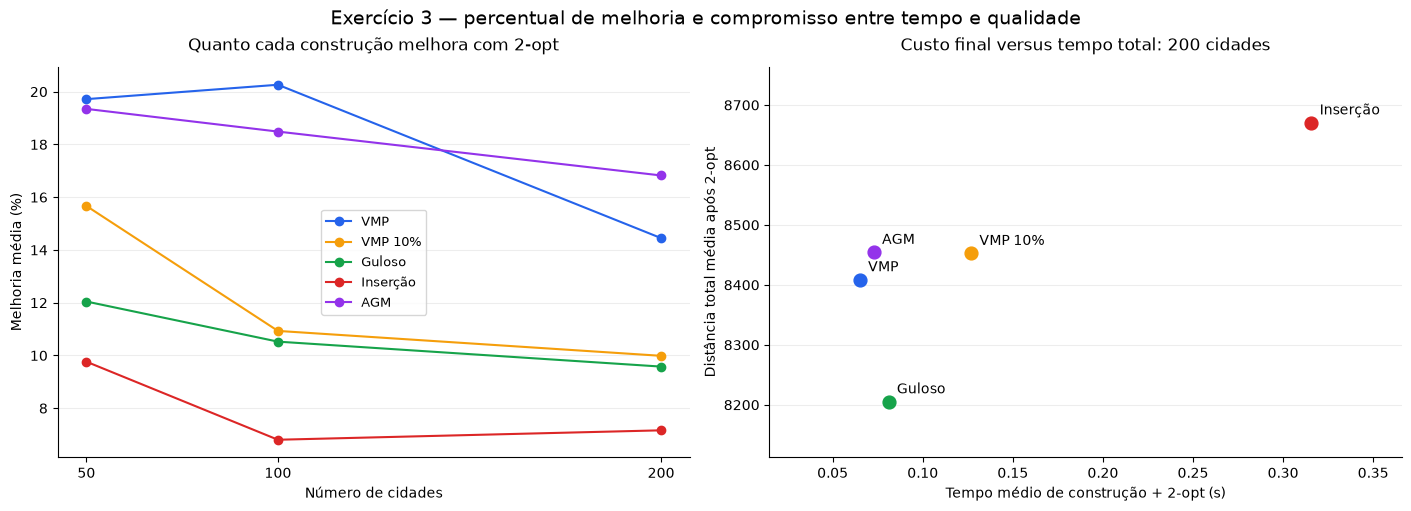

In [4]:
nomes_3 = ['Vizinho mais próximo', 'VMP com múltiplos inícios (10%)',
           'Guloso', 'Inserção mais barata', 'AGM']
rotulos_3 = ['VMP', 'VMP 10%', 'Guloso', 'Inserção', 'AGM']
fig, eixos = plt.subplots(1, 3, figsize=(17, 5), layout='constrained')
for ax, n in zip(eixos, (50, 100, 200)):
    grupo = [next(r for r in resumo_3 if r['n'] == n and r['Método'] == nome)
             for nome in nomes_3]
    antes = ax.bar([i - 0.18 for i in range(5)],
                   [r['Custo inicial médio'] for r in grupo], 0.36,
                   label='Antes do 2-opt', color='#94a3b8')
    depois = ax.bar([i + 0.18 for i in range(5)],
                    [r['Custo final médio'] for r in grupo], 0.36,
                    label='Após 2-opt', color='#2563eb')
    ax.bar_label(antes, fmt='%.0f', padding=3, fontsize=8, rotation=90)
    ax.bar_label(depois, fmt='%.0f', padding=3, fontsize=8, rotation=90)
    ax.margins(y=0.25)
    ax.set_xticks(range(5), rotulos_3, rotation=20)
    preparar_eixo(ax, f'{n} cidades', 'Distância total média')
    ax.legend(fontsize=9)
fig.suptitle('Exercício 3 — custos médios antes e depois do 2-opt (três sementes)',
              fontsize=14)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
dispersao_antes, dispersao_depois, instancias = [], [], []
for n in (50, 100, 200):
    for s in (0, 1, 2):
        grupo = [r for r in resultados_3 if r['n'] == n and r['Semente'] == s]
        inicial = [r['Custo inicial'] for r in grupo]
        final = [r['Custo após 2-opt'] for r in grupo]
        dispersao_antes.append(100 * (max(inicial) - min(inicial)) / min(inicial))
        dispersao_depois.append(100 * (max(final) - min(final)) / min(final))
        instancias.append(f'{n}\ns{s}')
ax = eixos[0]
ax.plot(range(9), dispersao_antes, 'o-', color='#94a3b8',
        label=f'Antes: média {mean(dispersao_antes):.2f}%')
ax.plot(range(9), dispersao_depois, 'o-', color='#2563eb',
        label=f'Depois: média {mean(dispersao_depois):.2f}%')
ax.set_xticks(range(9), instancias)
ax.set_xlabel('Número de cidades e semente (s)')
preparar_eixo(ax, 'Diferenças entre métodos por instância',
              '100 × (maior custo − menor custo) / menor custo (%)')
ax.legend(fontsize=9)
ax = eixos[1]
for pos, s in enumerate((0, 2)):
    grupo = [r for r in resultados_3 if r['n'] == 50 and r['Semente'] == s]
    nomes = (['Inserção mais barata', 'VMP com múltiplos inícios (10%)'] if s == 0
             else ['Guloso', 'Vizinho mais próximo'])
    for desloc, nome in enumerate(nomes):
        r = next(r for r in grupo if r['Método'] == nome)
        xs = [pos * 3 + desloc * 0.8, pos * 3 + desloc * 0.8 + 0.32]
        barras = ax.bar(xs, [r['Custo inicial'], r['Custo após 2-opt']],
                         width=0.3, color=['#94a3b8', '#2563eb'])
        ax.bar_label(barras, fmt='%.2f', padding=3, fontsize=8, rotation=90)
ax.set_xticks([0.16, 0.96, 3.16, 3.96],
              ['Inserção\nsemente 0', 'VMP 10%\nsemente 0',
               'Guloso\nsemente 2', 'VMP\nsemente 2'])
ax.margins(y=0.3)
preparar_eixo(ax, 'Contraexemplos: melhor início ≠ melhor resultado',
              'Distância total (50 cidades)')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#94a3b8'),
                    plt.Rectangle((0, 0), 1, 1, color='#2563eb')],
          labels=['Antes do 2-opt', 'Após 2-opt'], fontsize=9)
fig.suptitle('Exercício 3 — redução das diferenças e inversão da classificação',
              fontsize=14)
plt.show()

fig, eixos = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')
for m, nome in enumerate(nomes_3):
    valores = [next(r['Melhoria média (%)'] for r in resumo_3
                    if r['n'] == n and r['Método'] == nome) for n in (50, 100, 200)]
    eixos[0].plot([50, 100, 200], valores, 'o-', color=cores_pcv[m], label=rotulos_3[m])
    r = next(r for r in resumo_3 if r['n'] == 200 and r['Método'] == nome)
    eixos[1].scatter(r['Tempo médio total (s)'], r['Custo final médio'],
                     s=85, color=cores_pcv[m])
    eixos[1].annotate(rotulos_3[m], (r['Tempo médio total (s)'], r['Custo final médio']),
                     xytext=(6, 6), textcoords='offset points', fontsize=10)
preparar_eixo(eixos[0], 'Quanto cada construção melhora com 2-opt',
              'Melhoria média (%)')
eixos[0].set_xticks([50, 100, 200])
eixos[0].set_xlabel('Número de cidades')
eixos[0].legend(fontsize=9)
preparar_eixo(eixos[1], 'Custo final versus tempo total: 200 cidades',
              'Distância total média após 2-opt')
eixos[1].set_xlabel('Tempo médio de construção + 2-opt (s)')
eixos[1].margins(x=0.2, y=0.2)
fig.suptitle('Exercício 3 — percentual de melhoria e compromisso entre tempo e qualidade',
              fontsize=14)
plt.show()


### Discussão do exercício 3

**1. Qual heurística costuma produzir as melhores soluções iniciais?**

Neste conjunto de experimentos, o guloso apresentou o menor custo inicial médio em **todos os três tamanhos**. Para 50 cidades, seu custo médio foi **4763,13**, seguido da inserção mais barata com **4813,85** e do VMP com múltiplos inícios com **4838,29**. Para 100 cidades, o guloso teve **6727,86**, contra **6849,96** do VMP com múltiplos inícios e **6895,55** da inserção. Para 200 cidades, o guloso chegou a **9084,83**, enquanto a inserção teve **9339,74** e o VMP com múltiplos inícios **9391,55**. Assim, a vantagem média do guloso apareceu de forma consistente entre os tamanhos testados.

Isso não significa que o guloso venceu em cada instância individual. Com 50 cidades e semente 0, por exemplo, a inserção mais barata teve custo **4602,01**, menor que os **4616,70** do guloso. Na mesma instância, o VMP com múltiplos inícios ficou muito próximo, com **4603,79**. Esse exemplo mostra por que considero importante olhar tanto as médias quanto as linhas individuais da tabela.

Uma possível explicação para o bom desempenho médio do guloso é que ele considera as arestas de toda a instância, em vez de decidir apenas a partir da cidade atual. Já a AGM minimiza o custo de uma árvore, que é um objetivo diferente de minimizar um ciclo: a ordem de visita definida pela pré-ordem pode gerar ligações maiores na rota. O VMP com múltiplos inícios reduz a dependência do ponto de partida, mas conserva o critério local do vizinho mais próximo. Essas explicações ajudam a interpretar os resultados, porém não provam a superioridade geral do guloso. Minha conclusão se limita às três sementes de cada tamanho utilizadas aqui.

**2. Após a aplicação do 2-opt, as diferenças entre os métodos diminuem?**

Em média, sim, embora não desapareçam. Para comparar métodos na mesma instância, calculei a diferença relativa entre o maior e o menor custo como \(100(z_{\max}-z_{\min})/z_{\min}\). Depois fiz a média desse indicador nas nove instâncias, correspondentes a três tamanhos e três sementes. A diferença média caiu de **15,18% antes do 2-opt para 7,85% depois dele**. Portanto, a busca local reduziu aproximadamente pela metade essa medida de dispersão entre as soluções.

O motivo é que o 2-opt pode corrigir ligações desfavoráveis criadas pelas heurísticas construtivas. Ele retira duas arestas e reconecta os segmentos, invertendo a ordem de um deles quando necessário. Como as distâncias são simétricas, inverter o sentido das arestas internas do segmento não muda seu custo; a melhoria depende das ligações substituídas. Quando a troca reduz a distância total, ela é aceita, e o procedimento continua procurando outras melhorias.

Os métodos que começaram com custos maiores tiveram espaço para reduções relevantes. Para 100 cidades, o VMP simples melhorou em média **20,26%**, enquanto o guloso melhorou **10,52%**. Mesmo assim, o custo final médio do guloso foi **6013,29**, ligeiramente menor que os **6043,75** do VMP simples. Portanto, uma porcentagem de melhoria maior não significa, por si só, uma solução final melhor: ela também depende do custo de partida. A comparação precisa considerar o custo final, além da redução percentual.

Também não podemos concluir que as diferenças diminuíram em cada instância ou que os métodos ficaram equivalentes. A queda de 15,18% para 7,85% é uma observação média. Como cada construção pode levar a um mínimo local diferente, parte da diferença permanece mesmo depois das melhorias.

**3. A melhor solução inicial sempre conduz à melhor solução final?**

Não. Um contraexemplo aparece na instância de **50 cidades e semente 0**. A inserção mais barata forneceu a menor rota inicial, com custo **4602,01**, enquanto o VMP com múltiplos inícios começou com **4603,79**, um custo um pouco maior. Após o 2-opt, a inserção terminou em **4016,74**, e o VMP com múltiplos inícios terminou em **3939,77**. Ou seja, a rota que começou ligeiramente pior terminou aproximadamente **76,97 unidades menor**. Esse único caso já é suficiente para refutar a afirmação de que o melhor início sempre produz o melhor resultado final.

Outro exemplo é a semente 2 com 50 cidades: o guloso começou em **4568,39**, melhor que os **5230,35** do VMP simples. Depois da busca, o guloso terminou em **4056,94**, enquanto o VMP simples chegou a **3888,14**. Nesse caso, até uma diferença inicial relativamente grande foi revertida pela busca local.

Minha interpretação é que o custo inicial informa o tamanho da rota, mas não descreve todas as oportunidades de melhoria presentes nela. Uma solução de menor custo pode estar próxima de um mínimo local menos favorável; outra, inicialmente maior, pode permitir uma sequência de trocas que leva a uma região melhor. Além da solução inicial, a ordem de avaliação das trocas influencia o caminho seguido, porque uma troca aceita altera as possibilidades seguintes. Por isso, eu avaliaria cada combinação de construção e busca local pelo resultado final, sem presumir que a classificação inicial será mantida.

**4. Duas soluções iniciais diferentes podem conduzir a mínimos locais diferentes?**

Sim. Um mínimo local em relação ao 2-opt é uma rota para a qual nenhuma troca válida de duas arestas reduz o custo. Isso não quer dizer que ela seja a melhor rota de todas: apenas que não há uma melhoria disponível dentro dessa vizinhança. Uma solução globalmente melhor pode exigir outra modificação, uma troca de mais arestas ou uma sequência que inclua temporariamente uma piora, o que a busca utilizada não aceita.

Na instância de 50 cidades e semente 0, o VMP com múltiplos inícios terminou com custo **3939,77**, a inserção em **4016,74** e o guloso em **4164,30**. Os custos finais distintos mostram que as construções não chegaram todas à mesma qualidade de solução, mesmo recebendo o mesmo procedimento de melhoria. Cada rota inicial oferece um conjunto diferente de ligações para substituir, e as melhorias sucessivas podem conduzir a mínimos locais diferentes.

Também pode acontecer o contrário: soluções iniciais diferentes terminarem no mesmo custo. Nessa mesma instância, a AGM e o guloso terminaram em aproximadamente **4164,30**. Isso é compatível com a chegada ao mesmo ciclo, mas a igualdade dos custos, sozinha, não demonstra que as rotas sejam idênticas; seria necessário comparar as sequências, considerando rotações e inversões do ciclo.

Na implementação, o critério de parada é realizar uma passagem completa pelos segmentos sem reduzir o custo total. Uma única troca que não melhora a rota não seria suficiente, porque outras trocas ainda poderiam ser vantajosas. A dependência dos mínimos locais ajuda a explicar o interesse em diferentes soluções iniciais e em estratégias de diversificação: elas dão à busca a oportunidade de explorar outras regiões, em vez de depender de apenas um ponto de partida.

**5. A qualidade da solução inicial continua sendo importante quando utilizamos busca local?**

Sim, mas eu não a avaliaria isoladamente. A construção inicial determina a rota sobre a qual o 2-opt vai trabalhar e influencia quais melhorias podem ser realizadas. Uma rota inicial de boa qualidade já oferece um custo baixo caso o tempo disponível para a busca seja limitado. Porém, como os contraexemplos mostram, começar melhor não garante terminar melhor, nem significa que a busca local será necessariamente mais rápida.

As médias finais mostram essa relação entre construção e melhoria. Com 50 cidades, o guloso teve a melhor média inicial, mas o VMP com múltiplos inícios teve a melhor média final, **4071,42**, contra **4184,24** do guloso. Já com 100 e 200 cidades, o guloso manteve a melhor média final, com **6013,29** e **8205,14**, respectivamente. Portanto, o efeito da escolha inicial depende também da forma como ela interage com a busca local naquela instância.

Para escolher um método na prática, eu consideraria **custo final e tempo total**, somando construção e 2-opt. Com 200 cidades, o guloso teve tempo total médio de cerca de **0,0810 s** e custo final médio **8205,14**. A inserção mais barata gastou cerca de **0,3157 s** e terminou com média **8670,33**. Nesse tamanho e nessas sementes, o guloso foi vantajoso tanto em qualidade final quanto em tempo total quando comparado à inserção. O VMP simples foi mais rápido que o guloso em média, cerca de **0,0650 s**, mas terminou com custo maior, **8408,88**, mostrando uma troca entre tempo e qualidade.

Uma estratégia que eu consideraria é gerar rotas por diferentes construções, aplicar o 2-opt em cada uma e guardar a melhor solução final. Isso custa mais processamento, mas aproveita o fato de que os métodos podem chegar a mínimos locais diferentes. Seria importante aplicar a busca a mais de uma rota, em vez de selecionar somente a menor rota construtiva antes do 2-opt, pois essa seleção poderia descartar um início que produziria o melhor resultado final.

Por fim, os experimentos utilizaram **três sementes por tamanho**, e as distâncias são euclidianas nas instâncias geradas. Eles permitem justificar as conclusões sobre os casos avaliados, mas não estabelecem uma classificação universal das heurísticas. Mais instâncias, distribuições diferentes de cidades e repetições das medições de tempo ajudariam a verificar a estabilidade das tendências observadas.


In [20]:
for construtor in (vmp_amostral, insercao_mais_barata, agm_pcv):
    for cidades_teste in ([], [[0, 0]], [[0, 0], [1, 0]],
                          [[0, 0], [0, 0], [1, 0], [0, 1]], Cidades(8)):
        validar_rota(construtor(cidades_teste), cidades_teste)
pequena = Cidades(8, rseed=7)
assert vmp_amostral(pequena, 1, 7) == vmp_amostral(pequena, 1, 7)
assert math.isclose(tamanho_rota(vmp_amostral(pequena, 1, 7)), tamanho_rota(vmp_completa(pequena)))
for nome, metodo in metodos_3.items():
    rota = alterar_rota(metodo(pequena).copy())
    for i, j in todos_segmentos(len(rota)):
        candidata = rota.copy()
        reverter(candidata, i, j)
        assert tamanho_rota(candidata) >= tamanho_rota(rota) - 1e-8
print('Verificações concluídas: rotas válidas, amostragem completa e parada em ótimo local 2-opt.')


Verificações concluídas: rotas válidas, amostragem completa e parada em ótimo local 2-opt.
